# Generative Modeling Crash Course
Diffusion Models & Flow Matching | Week 1 of 4 | Graduate level | 6–8 hours

Framework:
* TensorFlow 2.x
* Keras
* NumPy
* Matplotlib
* SciPy

All implementation exercises use TensorFlow.

In [1]:
import numpy as np
import scipy as sp
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras

In [2]:
# Instantiate a numpy random number generator for distributions
rng = np.random.default_rng(42)

## 1. Learning Objectives
* Distinguish discriminative and generative models.
* Describe sampling, probability density, and Gaussian mixtures.
* Calculate empirical mean and covariance.
* Explain KL divergence and maximum likelihood.
* Explain deterministic ODEs and stochastic SDEs.
* Implement and visualize a 2D Gaussian mixture using TensorFlow.

## 2. What is a generative model?

A discriminative model learns a conditional distribution $p_{θ}(y|x)$, for example predicting a class from an image. A generative model aims to represent or sample from the data distribution $p_{data}(x)$.

<center>$p_{θ}(x) ≈ p_{data}(x)$</center>

A common approach begins with simple noise $z$ sampled from $\mathbb{N}(0, 1)$, then transforms it using a learned function $G_{θ}$.

<center>$z \sim \mathbb{N}(0, 1)$</center>

<center>$x = G_{θ}(z)$</center>

Some generative models provide an explicit probability density; others primarily learn a sampling mechanism. Diffusion and flow matching are particularly useful examples of the latter.

## 3. Probability Foundations


### 3.1 Multivariate Gaussian

For a d-dimensional Gaussian with mean $μ$ and covariance $Σ$:
<center>
$\Large p(x) = \left(\frac{1}{(2π)^{\frac{d}{2}}\left|\Sigma\right|^{\frac{1}{2}}} \right) \exp\left(−\frac{1}{2} (x−μ)^{T} Σ^{-1} (x−μ)\right)$.
</center>
<br>

Here $d$ is the dimension, $μ$ is the mean vector, $Σ$ is the covariance matrix, and $|Σ|$ is its determinant.\
For a 2D standard normal, $μ = (0, 0)$ and $Σ = I$.

The diagonal entries of $Σ$ are variances. The off-diagonal entries are covariances. For standard deviations $σ₁$, $σ₂$ and correlation $ρ$:
<center>
$
\Sigma = \begin{bmatrix}
\sigma_1^2 & \rho\sigma_1\sigma_2 \\
\rho\sigma_1\sigma_2 & \sigma_2^2
\end{bmatrix}
$
</center>
<br>

Experiment:\
Change each mean, standard deviation, and correlation. Predict how the contours shift, stretch, and rotate. A nonzero correlation tilts the elliptical contours.

In [3]:
n = 1000
d = 4
x = rng.normal(rng.random()*5, rng.random()*10, (n, d))
labels = tf.random.uniform(
      (n, ), minval=0, maxval=d, dtype=tf.int32
  )

### Get mean and correlation from a random normal distribution

In [4]:
n = 1000
d = 4

x = rng.normal(rng.random()*10, rng.random()*10, (n, d))

def p(x):
  d = x.shape[1]
  mu = x.mean(axis=0)
  sigma = np.cov(x, rowvar=False)
  det = np.linalg.det(sigma)
  A = ((1/((2*np.pi)**(d/2)* np.sqrt(det))))
  P = A * np.exp(-(1/2)*(np.diag((x - mu) @ np.linalg.inv(sigma) @ (x - mu).T)))
  return P
P = p(x)
P[:10], P.shape

(array([4.88625467e-06, 5.48389911e-06, 3.09896954e-06, 3.32528778e-06,
        2.14838205e-06, 4.09042802e-06, 6.74285320e-06, 9.11784472e-06,
        1.24451302e-06, 6.65727883e-06]),
 (1000,))

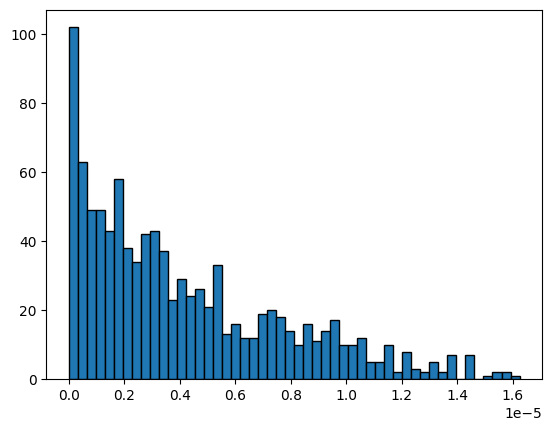

In [5]:
plt.hist(P, bins=50, edgecolor='k');

### Explore graphs of distributions

mu values: [(1, np.float64(4.0)), (3, np.float64(1.0)), (17, np.float64(-4.0)), (13, np.float64(-6.5)), (33, np.float64(-5.0)), (6, np.float64(-5.75)), (1, np.float64(-3.5)), (29, np.float64(-5.0)), (73, np.float64(-3.0)), (46, np.float64(-6.25)), (11, np.float64(7.0)), (1, np.float64(-5.0)), (1, np.float64(7.0)), (66, np.float64(-25.25)), (99, np.float64(7.5)), (31, np.float64(-10.5))]


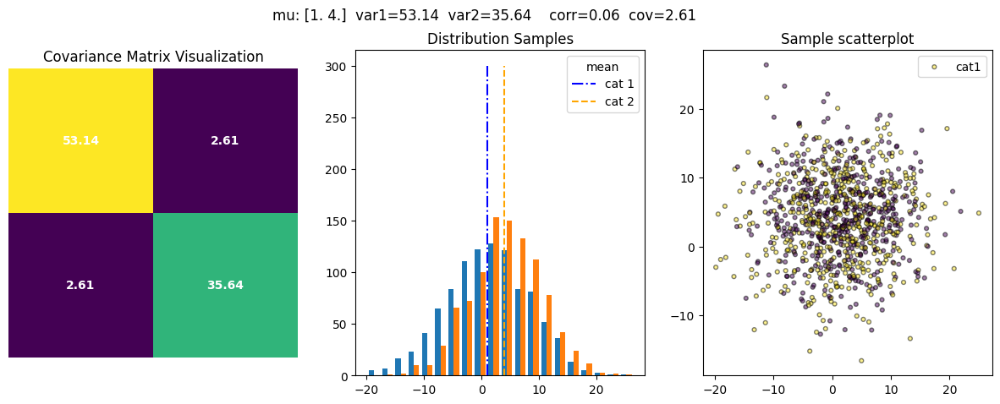

mean: [1. 4.]

covariance:
[[53.1441    2.611278]
 [ 2.611278 35.6409  ]]

samples:
[[ 4.77268037 -1.17270106]
 [-8.71106915  5.84606062]
 [-0.83514393 -0.07033564]
 ...
 [-6.28298916  3.05645057]
 [ 8.08055146 -2.45258832]
 [ 6.52435212  7.16097268]]
--------------------------------------------------



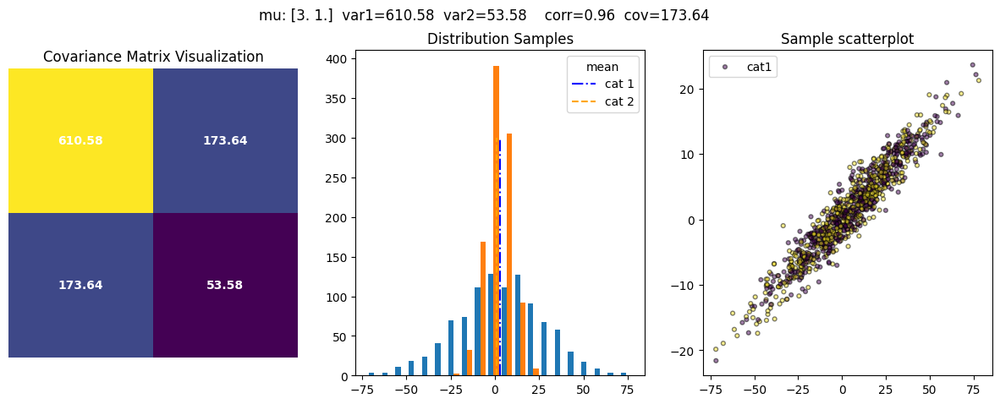

mean: [3. 1.]

covariance:
[[610.5841   173.642112]
 [173.642112  53.5824  ]]

samples:
[[ -5.05422924  -2.94629794]
 [ 57.38692182  17.42702713]
 [ 24.8033086    8.65291985]
 ...
 [ 76.44535635  22.15049369]
 [-19.92824429  -5.93602997]
 [ 14.5108903    3.74720497]]
--------------------------------------------------



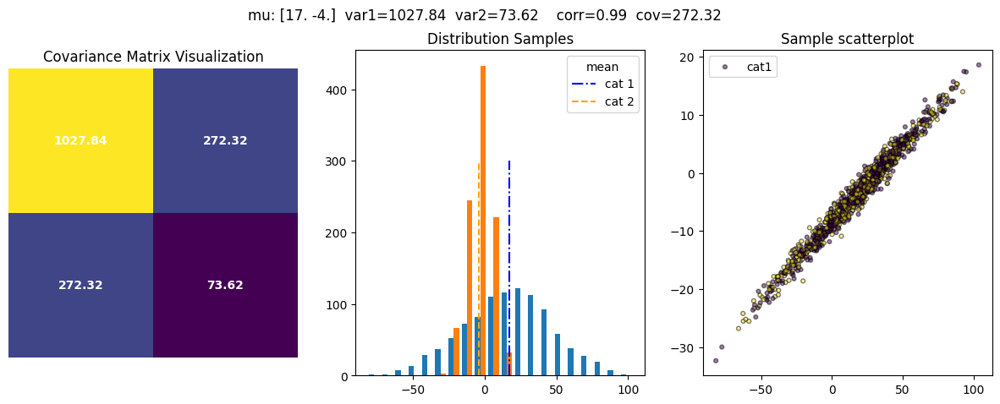

mean: [17. -4.]

covariance:
[[1027.8436    272.324052]
 [ 272.324052   73.6164  ]]

samples:
[[ -0.3578712   -9.99516852]
 [-21.09089133 -14.17329824]
 [ 46.63825324   5.22396229]
 ...
 [  1.56742149  -7.97593881]
 [-35.72551823 -17.13502738]
 [ 20.21785675  -2.25268105]]
--------------------------------------------------



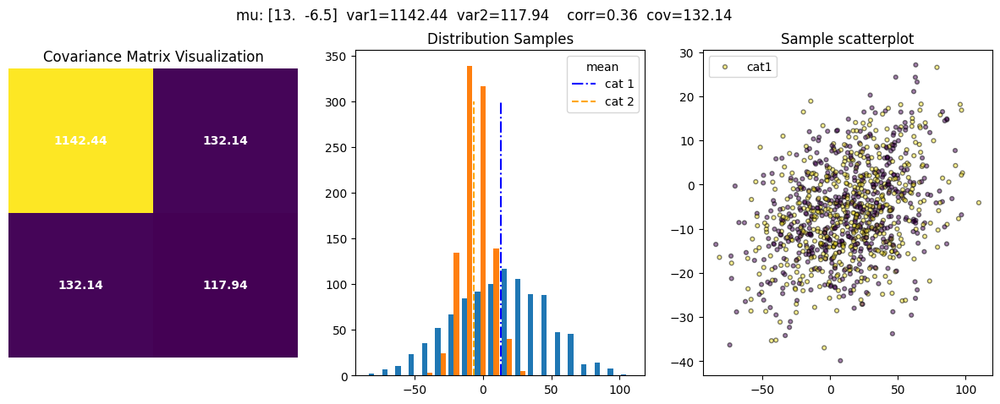

mean: [13.  -6.5]

covariance:
[[1142.44     132.14448]
 [ 132.14448  117.9396 ]]

samples:
[[ 11.29914156  -6.25764235]
 [-29.64911214 -21.01786064]
 [ 10.706142     5.27133951]
 ...
 [ 20.84459584  -2.73008764]
 [ 84.55174872  -9.57262921]
 [ 26.58132239 -12.00521556]]
--------------------------------------------------



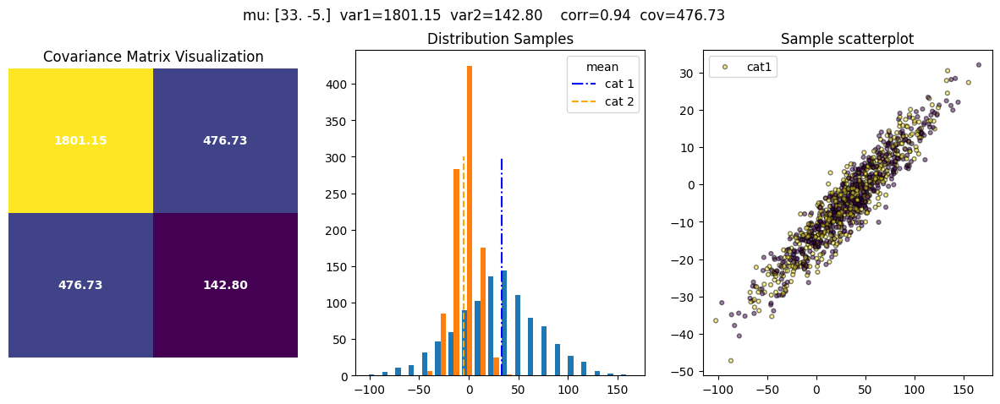

mean: [33. -5.]

covariance:
[[1801.1536   476.72852]
 [ 476.72852  142.8025 ]]

samples:
[[100.04807019  16.39874409]
 [ 21.83652643  -7.40840281]
 [ 62.36384579   3.16336384]
 ...
 [-27.07418497 -17.88982624]
 [ 28.54451867  -1.5185999 ]
 [103.04597655  13.35397898]]
--------------------------------------------------



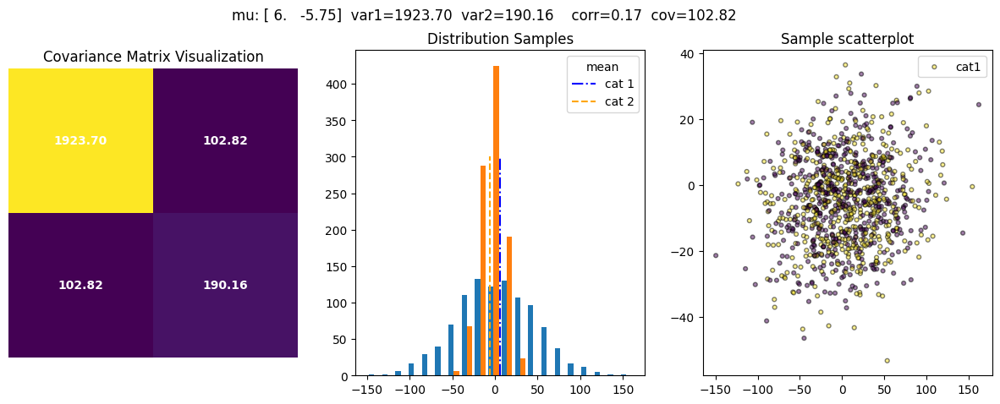

mean: [ 6.   -5.75]

covariance:
[[1923.6996    102.820998]
 [ 102.820998  190.1641  ]]

samples:
[[ -0.51223957   2.04769148]
 [ 81.42311543  -4.83139577]
 [-11.94327216  -0.32518224]
 ...
 [ 26.24773588 -18.21319772]
 [-50.60899921 -30.05035922]
 [ 75.98336003  -3.90097532]]
--------------------------------------------------



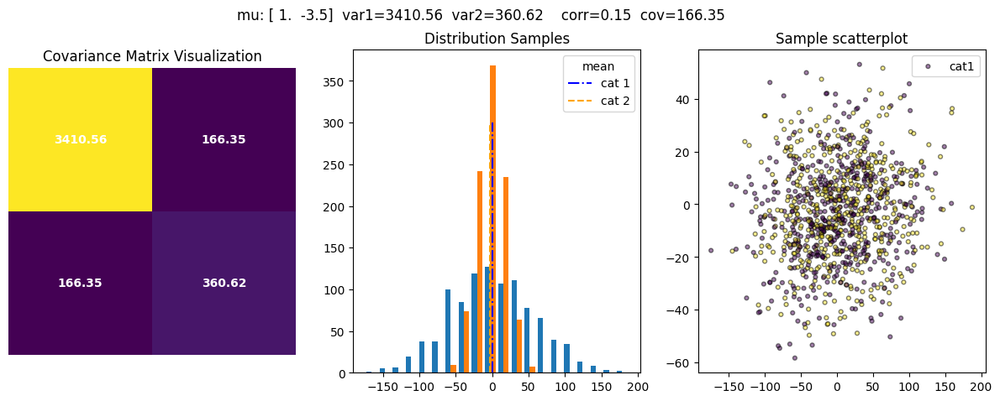

mean: [ 1.  -3.5]

covariance:
[[3410.56    166.3524]
 [ 166.3524  360.6201]]

samples:
[[ -3.90236329 -23.67038107]
 [-12.22621873   0.78451345]
 [ 26.97998572  36.09722438]
 ...
 [ 19.77571031 -17.30680407]
 [-18.49425992 -27.80977303]
 [ 66.30492119  16.95464924]]
--------------------------------------------------



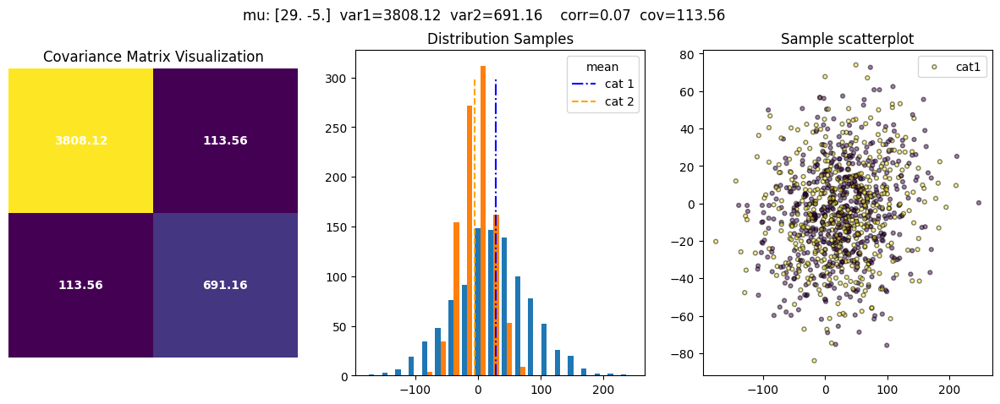

mean: [29. -5.]

covariance:
[[3808.1241    113.564913]
 [ 113.564913  691.1641  ]]

samples:
[[ 46.42049013 -12.16795191]
 [ 38.73999131  14.39301209]
 [ 19.49627959 -24.83581978]
 ...
 [  2.57960557 -67.25928531]
 [120.39899917  53.20367124]
 [ 26.85142082 -31.26642622]]
--------------------------------------------------



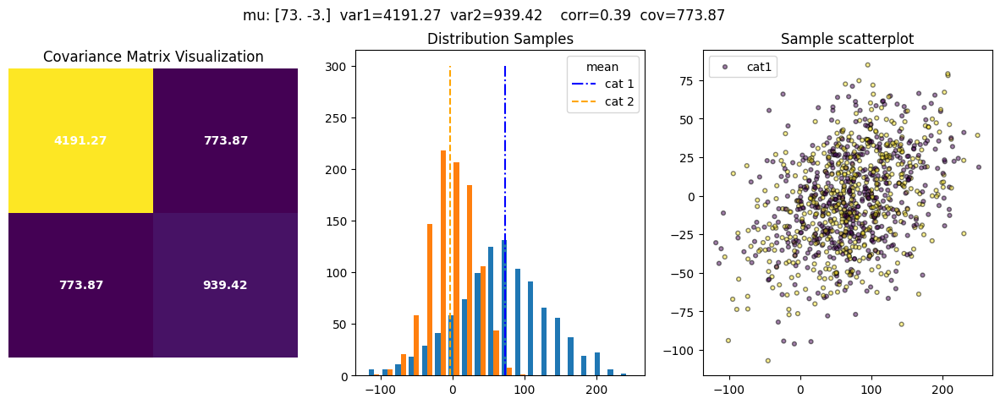

mean: [73. -3.]

covariance:
[[4191.2676   773.86959]
 [ 773.86959  939.4225 ]]

samples:
[[ 63.76111894 -34.93941877]
 [100.11298644 -38.05668304]
 [126.37142856  -2.74918085]
 ...
 [ -7.562306   -31.88734464]
 [ 79.69080507 -11.14550949]
 [ 62.00270514 -26.17251831]]
--------------------------------------------------



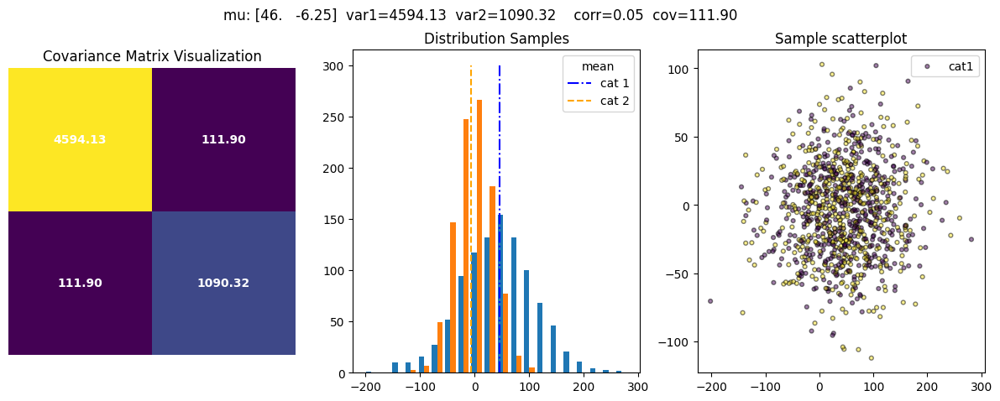

mean: [46.   -6.25]

covariance:
[[4594.1284   111.90478]
 [ 111.90478 1090.3204 ]]

samples:
[[ -26.88391108   27.67245285]
 [ 111.94576609   17.8688752 ]
 [  70.10596718   -3.77787606]
 ...
 [ 122.37373762  -62.63882834]
 [-129.51816375  -40.30438741]
 [ -32.72082802  -26.31746454]]
--------------------------------------------------



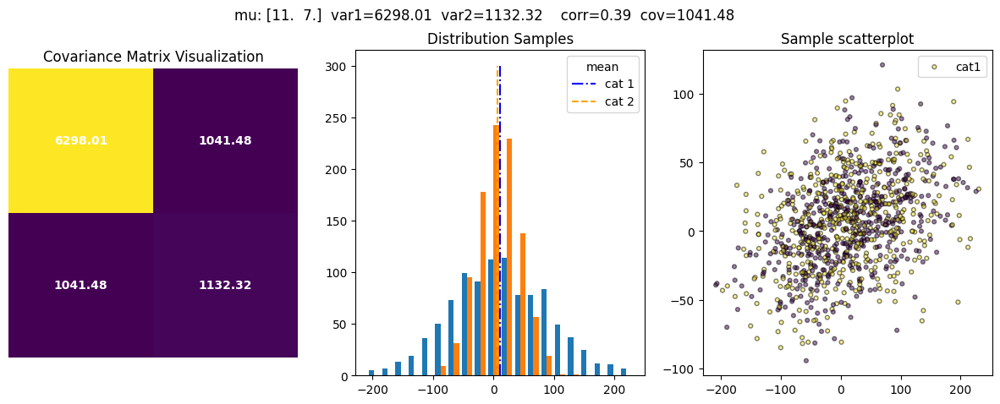

mean: [11.  7.]

covariance:
[[6298.0096  1041.48096]
 [1041.48096 1132.3225 ]]

samples:
[[ 96.34215696  24.22839794]
 [ 32.19608493  36.02584046]
 [-50.02772781 -23.17587794]
 ...
 [ 74.53454314   4.46977919]
 [ 18.49797792 -41.56869582]
 [-45.90699907  -9.14434297]]
--------------------------------------------------



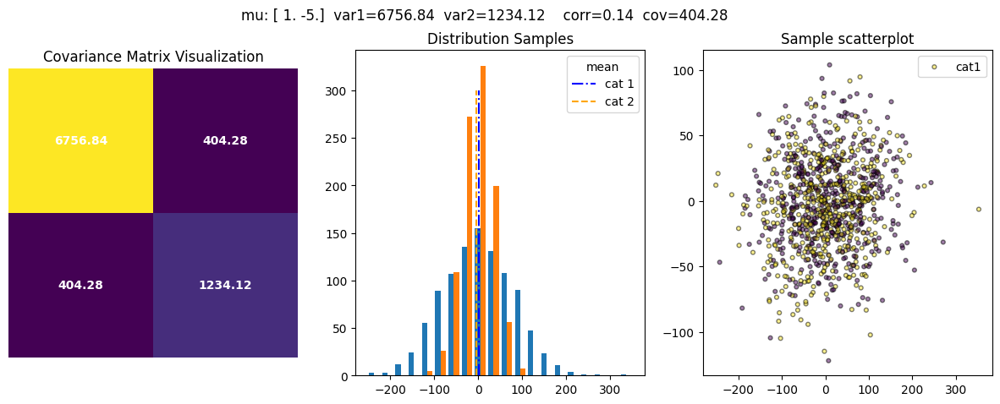

mean: [ 1. -5.]

covariance:
[[6756.84     404.27604]
 [ 404.27604 1234.1169 ]]

samples:
[[-63.7989342  -83.46273637]
 [-72.82501985  36.14895306]
 [-35.10734562  -6.58445469]
 ...
 [ 22.75718116  -4.60729802]
 [ 49.85296696  -4.1053893 ]
 [-45.71811241 -17.99720082]]
--------------------------------------------------



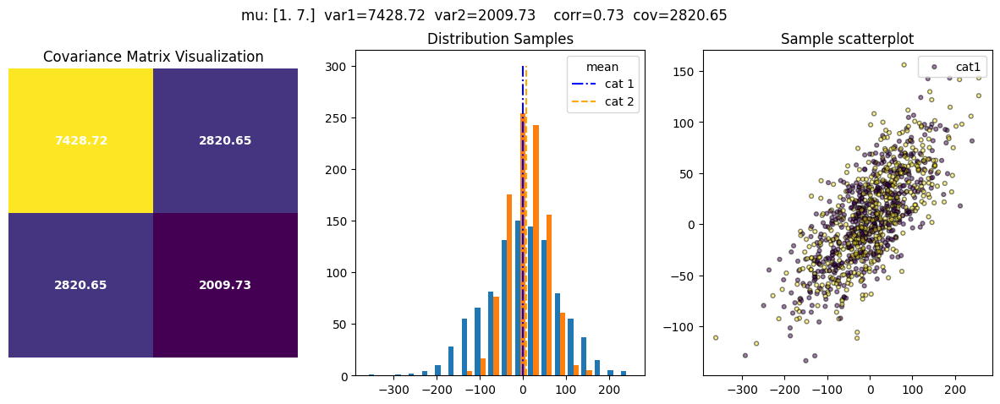

mean: [1. 7.]

covariance:
[[7428.7161   2820.645321]
 [2820.645321 2009.7289  ]]

samples:
[[ 22.67651771  35.00677673]
 [-43.94672249 -47.29526822]
 [  9.30623627  -5.6445634 ]
 ...
 [-11.38696157  11.10896997]
 [ 73.12264336  50.17689319]
 [-77.25879714 -14.06369321]]
--------------------------------------------------



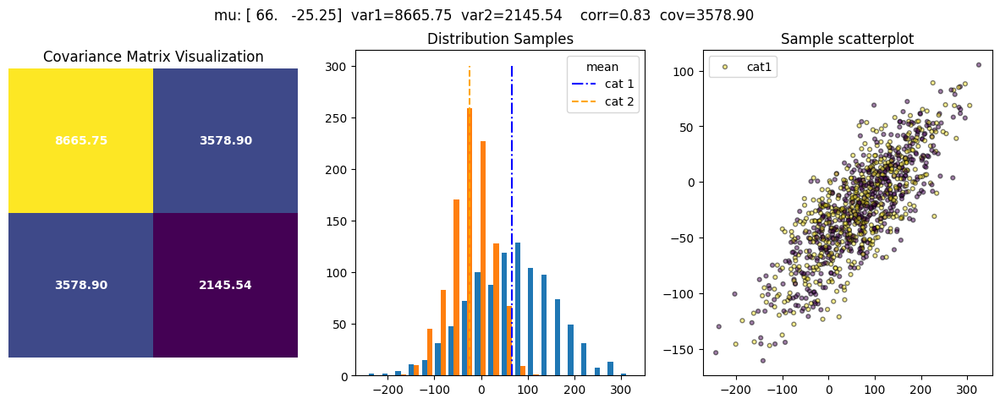

mean: [ 66.   -25.25]

covariance:
[[8665.7481   3578.900904]
 [3578.900904 2145.5424  ]]

samples:
[[  97.11977413   -6.97226105]
 [ 100.82195755  -12.95083657]
 [ 162.72236863   53.32511708]
 ...
 [   9.40722822  -50.98836435]
 [-130.5006364  -101.12707044]
 [  -5.9454333   -57.99081542]]
--------------------------------------------------



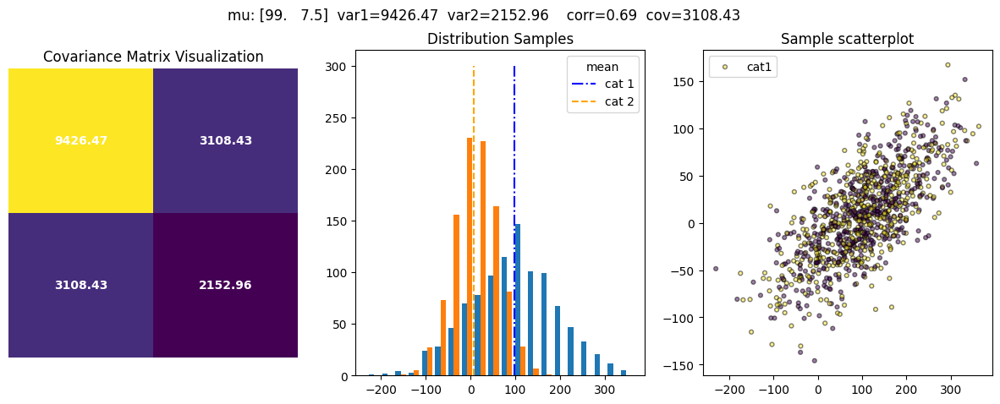

mean: [99.   7.5]

covariance:
[[9426.4681  3108.43344]
 [3108.43344 2152.96   ]]

samples:
[[   3.64576294  -34.63684918]
 [ 151.20473887   57.37257554]
 [ 101.83320125   16.83617486]
 ...
 [ 106.67748544   37.6831826 ]
 [ 152.86356325   60.31056249]
 [-119.82022091  -52.8570102 ]]
--------------------------------------------------



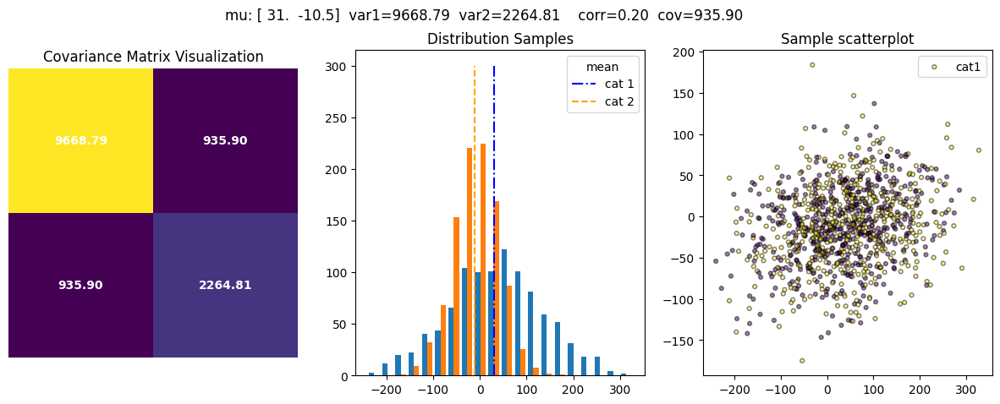

mean: [ 31.  -10.5]

covariance:
[[9668.7889   935.90494]
 [ 935.90494 2264.8081 ]]

samples:
[[  32.63068801   43.75004892]
 [ 131.14120857   73.00817986]
 [  92.51325017   98.42186863]
 ...
 [-135.23488414  -36.36130775]
 [   9.3475685     2.09621483]
 [ 182.61847752  -95.37295916]]
--------------------------------------------------



In [7]:
# Define initial variables
mu_vals = [(np.random.randint(10) * i+1, rng.choice([-1, 1]) * np.random.randint(10) * j - 5) for i, j in enumerate(np.arange(-1, 3, .25))]
n = len(mu_vals)
print(f'mu values: {mu_vals}')
sigma1_vals = np.sort(rng.uniform(1, 101, n).round(2))
sigma2_vals = np.sort(rng.uniform(.5, 50.1, n).round(2))
rho_vals = rng.uniform(0, 1, n).round(2)

# bundle the values together where one row is a set of experimental values
params = zip(mu_vals, sigma1_vals, sigma2_vals, rho_vals)

for p in params:
  mu = np.array([p[0][0], p[0][1]])
  n = len(mu)
  Sigma = np.array([
      [p[1]**2, p[1]*p[2]*p[3]],
      [p[1]*p[2]*p[3], p[2]**2]
  ])

  samples = rng.multivariate_normal(mean=mu, cov=Sigma, size=1000)
  labels = tf.random.uniform((len(samples),), 0, n, dtype=tf.int32)

  fig, ax = plt.subplots(1, 3, figsize=(15, 5), sharey=False)
  #fig.tight_layout()
  ax[0].imshow(Sigma, cmap='viridis')
  for i in range(Sigma.shape[0]):
    for j in range(Sigma.shape[1]):
        # Note: x-coordinate is column (j), y-coordinate is row (i)
        ax[0].text(j, i, f"{Sigma[i, j]:.2f}",
                ha="center", va="center", color="white", fontweight="bold")
  ax[0].axis('off')
  ax[0].set_title('Covariance Matrix Visualization')

  ax[1].hist(samples, bins=20)
  ax[1].set_title('Distribution Samples')
  ax[1].vlines(p[0][0], 0, 300, color='b', ls='-.')
  ax[1].vlines(p[0][1], 0, 300, color='orange', ls='--')
  ax[1].legend(['cat 1', 'cat 2'], title='mean')

  ax[2].scatter(samples[:, 0], samples[:, 1], c=labels, ec='k', s=12, alpha=.5)
  ax[2].set_title("Sample scatterplot")
  ax[2].legend(['cat1', 'cat2'])
  plt.suptitle(f'mu: {mu}  var1={Sigma[0][0]:.2f}  var2={Sigma[1][1]:.2f}  \
  corr={p[3]:.2f}  cov={Sigma[0][1]:.2f}')
  plt.show();

  print(f'mean: {mu}\n\ncovariance:\n{Sigma}\n\nsamples:\n{samples}\n{'-'*50}\n')


### 3.2 Gaussian Mixtures
A Gaussian mixture is a weighted sum of Gaussian components:
<center>$\Large p(x) = Σ_{k=1..K} \pi_{k} \mathbb{N}(x | μₖ, Σₖ)$, </center>
<br>
<center>$\pi_{k} ≥ 0$, $\Sigma \pi_{k} = 1$</center>

For the course toy dataset, use four equally weighted clusters with means $(−2,−2)$, $(−2,2)$,$ (2,−2)$, $(2,2)$ and covariance $0.15^{2}$ I for each component.
Because the mixture is symmetric, its population mean is $(0,0)$. The population covariance is:
<center>
$\Large
\text{cov(X)} = \begin{bmatrix}
4.0225 & 0 \\
0 & 4.0225
\end{bmatrix}
$
</center>

The total covariance includes both within-cluster variation ($0.0225$ per axis) and between-cluster variation ($4$ per axis). Empirical estimates from $5,000$ random samples will be close but not identical.

### 3.3 KL Divergence
<center>$\Large D_KL(p || q) = E[x\sim p]\log\left(\frac{p(x)}{q(x)}\right)$</center>

KL divergence is nonnegative and generally asymmetric. It is zero when the distributions agree almost
everywhere (under appropriate conditions). It appears in the variational derivation of diffusion models, even
though practical DDPM training commonly uses a simplified noise-prediction loss.

### 3.4
Maximum likelihood selects model parameters to maximize the likelihood of observed training samples. Equivalently, minimize the negative log-likelihood:
<center>$\Large θ^* = \text{argmin}_{θ} \left( −Σ_{i=1..N} \log p_θ(xᵢ) \right)$</center>

Not all generative models are trained by directly evaluating this expression; score-based and flow-matching methods use alternative training objectives.

## 4. Differential Equations: bridge to generative modeling


### 4.1 Ordinary Differential Equations (ODEs)
<center>$\Large \frac{dx}{dt} = v(x,t)$</center>

An ODE specifies a deterministic rate of change. For $dx/dt = −x$, the solution is $x(t) = x_0 e^{−t}$. Once the initial state is fixed, the trajectory is fixed.

Flow matching learns a time-dependent velocity field $v_θ(x,t)$ with a neural network. Integrating that field transports an initial noise sample toward the target distribution.
<center>$\large \frac{dx}{dt} = v_θ(x,t)$</center>

A basic numerical integrator is forward Euler:
<center>$\Large x_{n+1} = x_n + Δt v_θ(xₙ, tₙ)$</center>

### 4.2 Stochastic Differential Equations (SDEs)
<center>$\Large dx = f(x,t) dt + g(t) dWₜ$</center>
<br>

An SDE adds Brownian-motion noise. The Euler–Maruyama approximation is:
<center>$\Large xₙ₊₁ = xₙ + f(xₙ,tₙ)Δt + g(tₙ)√Δt εₙ$</center>
<br>
<center>$\large εₙ \sim \mathcal{N}(0,I)$</center>
<br>

The drift $f$ controls deterministic movement, while $g$ controls the strength of random perturbations. Diffusion models often use stochastic forward noising processes. Flow matching commonly uses deterministic ODE generation; diffusion models can also be sampled using probability-flow ODEs.

## 5. TensorFlow Programming Lab
Goal: Generate 5,000 samples from a four-component Gaussian mixture, calculate sample statistics, and visualize the data.

In [8]:
tf.random.set_seed(42)
np.random.seed(42)

In [9]:
centers = tf.constant([
    [-2., -2.],
    [-2., 2.],
    [2., -2.],
    [2., 2.]
], dtype=tf.float32)
centers

<tf.Tensor: shape=(4, 2), dtype=float32, numpy=
array([[-2., -2.],
       [-2.,  2.],
       [ 2., -2.],
       [ 2.,  2.]], dtype=float32)>

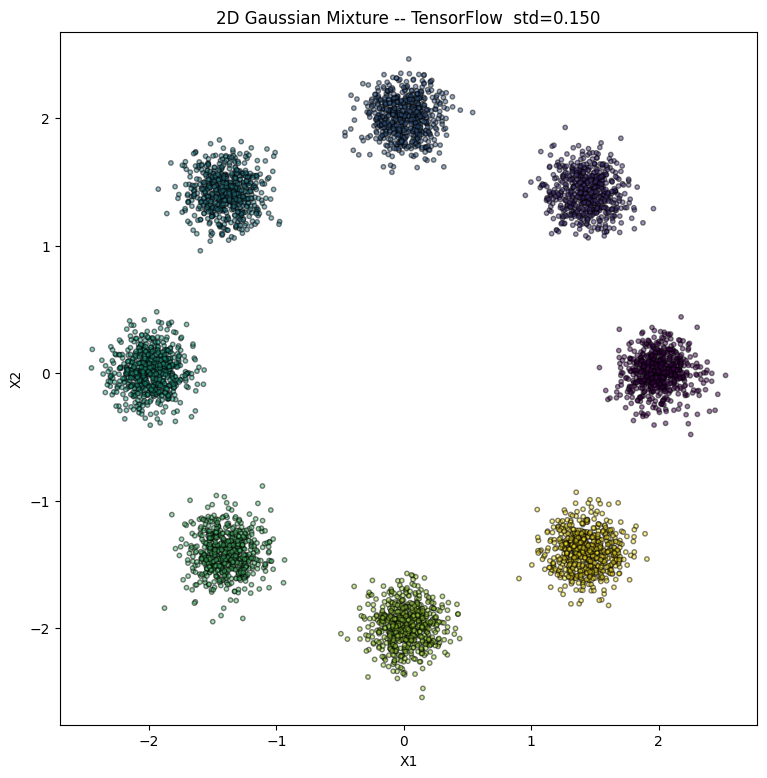


covariance matrix:
[[ 2.0106091  -0.01625636]
 [-0.01625636  2.0192602 ]]

Empirical mean:
[-0.01532783 -0.00732551]

Empirical covariance:
[[ 2.0106091  -0.01625636]
 [-0.01625636  2.0192602 ]]

tf.Tensor(
[[-1.2320186   1.4808438 ]
 [-0.23207445  2.1513898 ]
 [-1.5314748   1.5422269 ]
 ...
 [ 1.4759959  -1.7139927 ]
 [ 1.9993106   0.04292322]
 [ 1.2629554  -1.4204959 ]], shape=(5000, 2), dtype=float32) 

 tf.Tensor(
[[ 2.0106091  -0.01625636]
 [-0.01625636  2.0192602 ]], shape=(2, 2), dtype=float32)


In [15]:
n_samples = 5000
sigma = 0.15


def make_data(n, sigma, centers, plot=True):
  num_cat = len(centers)
  labels = tf.random.uniform(
      (n, ), minval=0, maxval=num_cat, dtype=tf.int32
  )
  noise = tf.random.normal((n, 2), stddev=sigma)
  X = tf.gather(centers, labels) + noise
  mean = tf.reduce_mean(X, axis=0)
  X_centered = X - mean

  covariance = tf.matmul(
      X_centered, X_centered, transpose_a=True
  ) / tf.cast(n - 1, tf.float32)
  if plot:
    plt.figure(figsize=(9, 9))
    plt.scatter(X_centered[:, 0].numpy(), X_centered[:, 1].numpy(), s=10, alpha=0.5, ec='k', c=labels.numpy(), cmap='viridis')
    plt.axis('equal')
    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.title(f'2D Gaussian Mixture -- TensorFlow  std={sigma:.3f}')
    plt.show();

  print(f'\ncovariance matrix:\n{covariance}\n')
  print(f'Empirical mean:\n{mean.numpy()}\n')
  print(f'Empirical covariance:\n{covariance}\n')
  return X, labels, covariance

X, labels, cov = make_data(n_samples, sigma, centers)

print(X, '\n\n', cov)


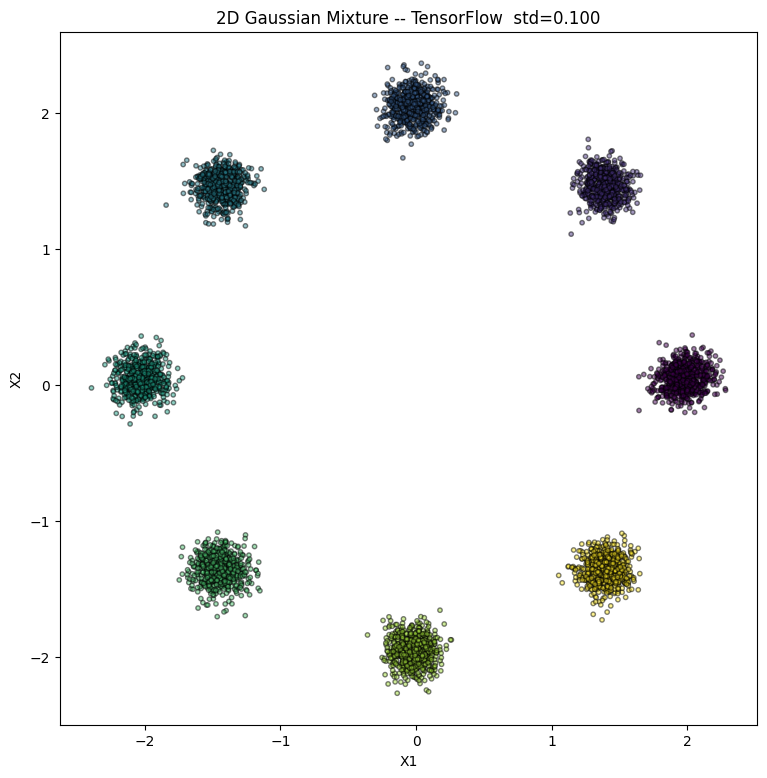


covariance matrix:
[[ 2.0119479  -0.01035949]
 [-0.01035949  2.0074167 ]]

Empirical mean:
[ 0.02185606 -0.04965498]

Empirical covariance:
[[ 2.0119479  -0.01035949]
 [-0.01035949  2.0074167 ]]



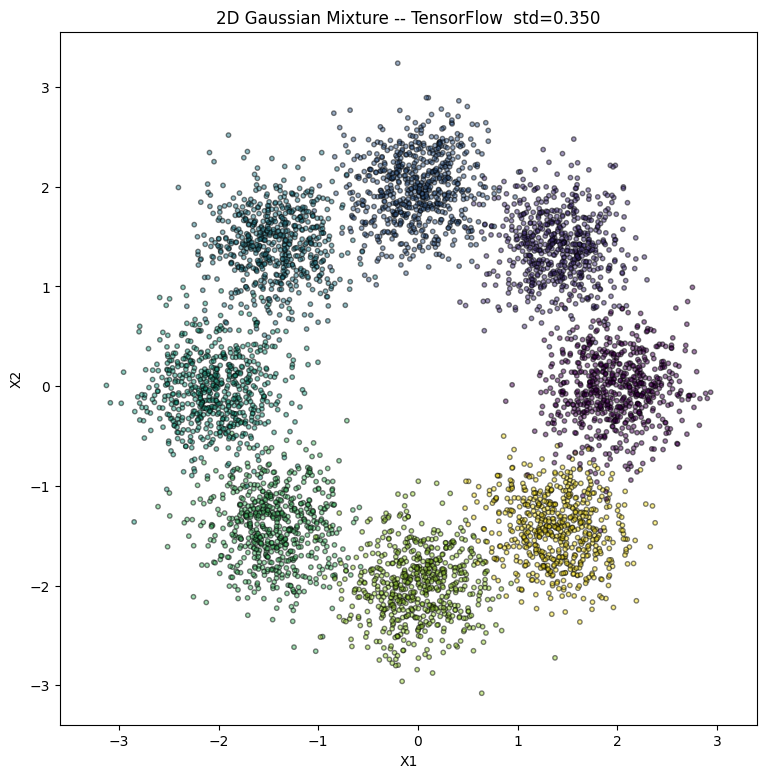


covariance matrix:
[[2.1354332  0.00250428]
 [0.00250428 2.1193497 ]]

Empirical mean:
[0.02091973 0.02928311]

Empirical covariance:
[[2.1354332  0.00250428]
 [0.00250428 2.1193497 ]]



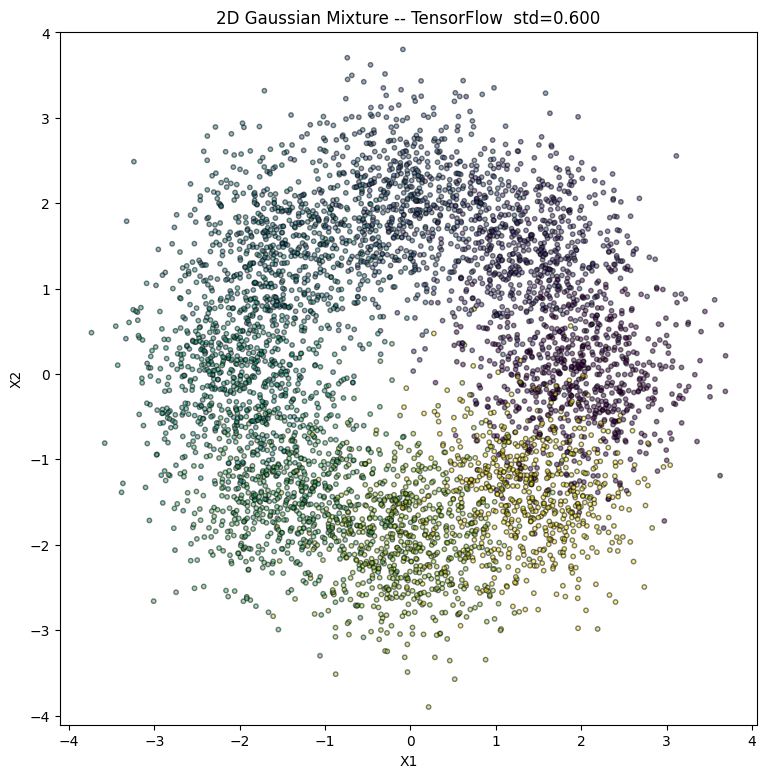


covariance matrix:
[[2.4001782e+00 3.5905262e-04]
 [3.5905262e-04 2.3538716e+00]]

Empirical mean:
[ 0.02201647 -0.00430797]

Empirical covariance:
[[2.4001782e+00 3.5905262e-04]
 [3.5905262e-04 2.3538716e+00]]



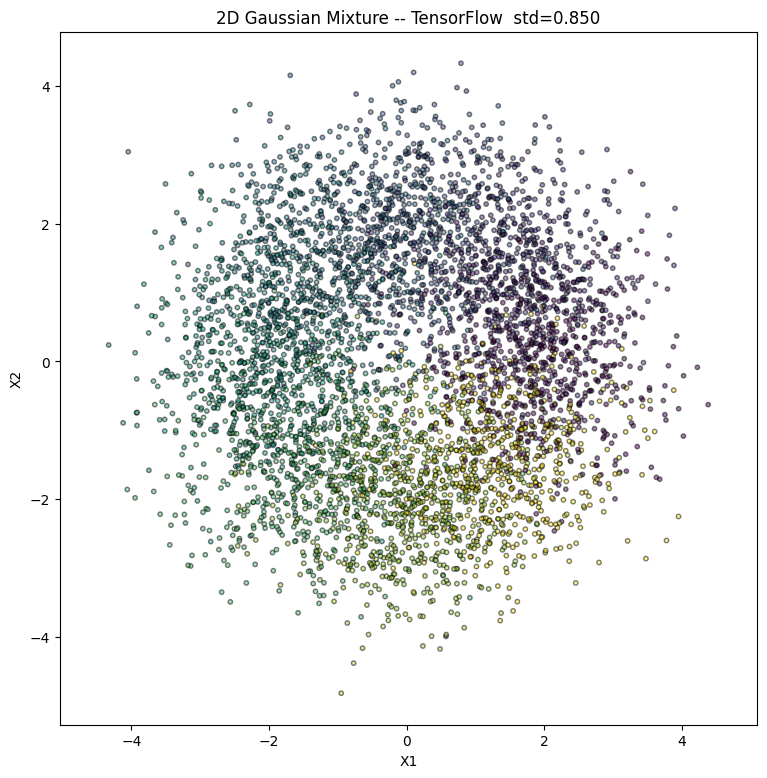


covariance matrix:
[[2.724206   0.05651412]
 [0.05651412 2.7652016 ]]

Empirical mean:
[0.0134155 0.0108045]

Empirical covariance:
[[2.724206   0.05651412]
 [0.05651412 2.7652016 ]]



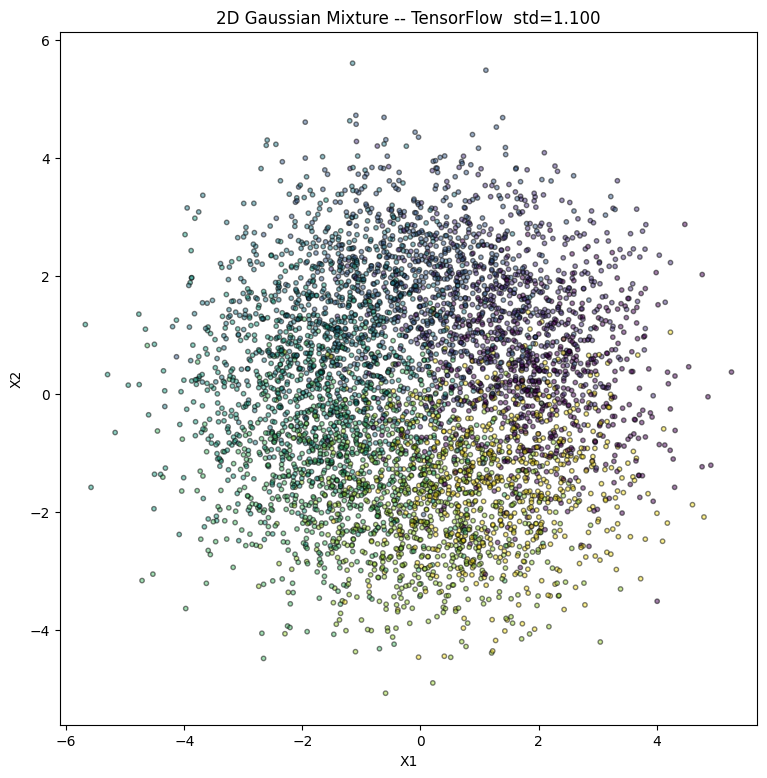


covariance matrix:
[[3.1794829e+00 5.3982489e-04]
 [5.3982489e-04 3.1470513e+00]]

Empirical mean:
[-0.01873745  0.0065027 ]

Empirical covariance:
[[3.1794829e+00 5.3982489e-04]
 [5.3982489e-04 3.1470513e+00]]



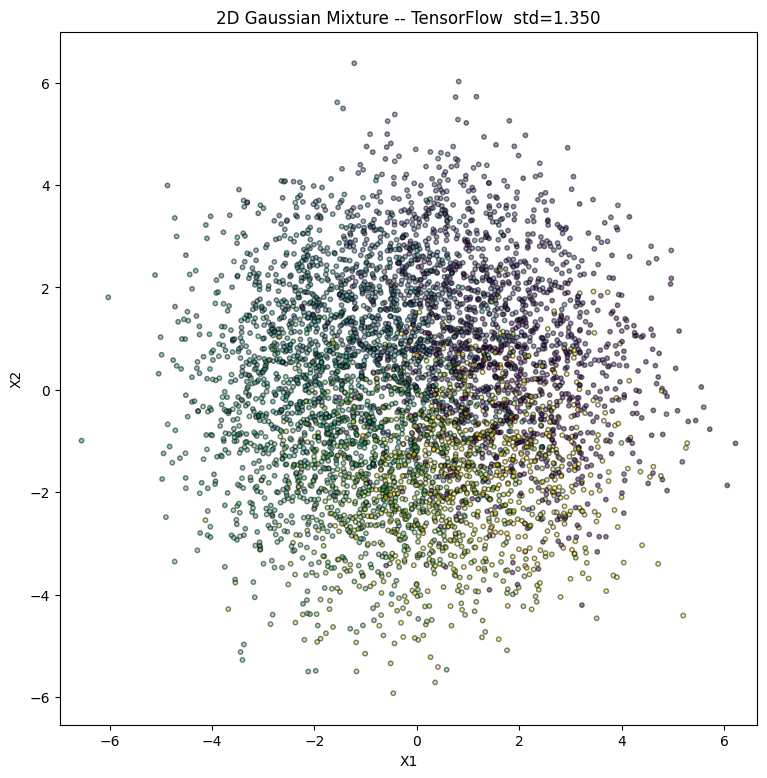


covariance matrix:
[[ 3.8531175  -0.02700021]
 [-0.02700021  3.8595536 ]]

Empirical mean:
[ 0.02323261 -0.01212768]

Empirical covariance:
[[ 3.8531175  -0.02700021]
 [-0.02700021  3.8595536 ]]



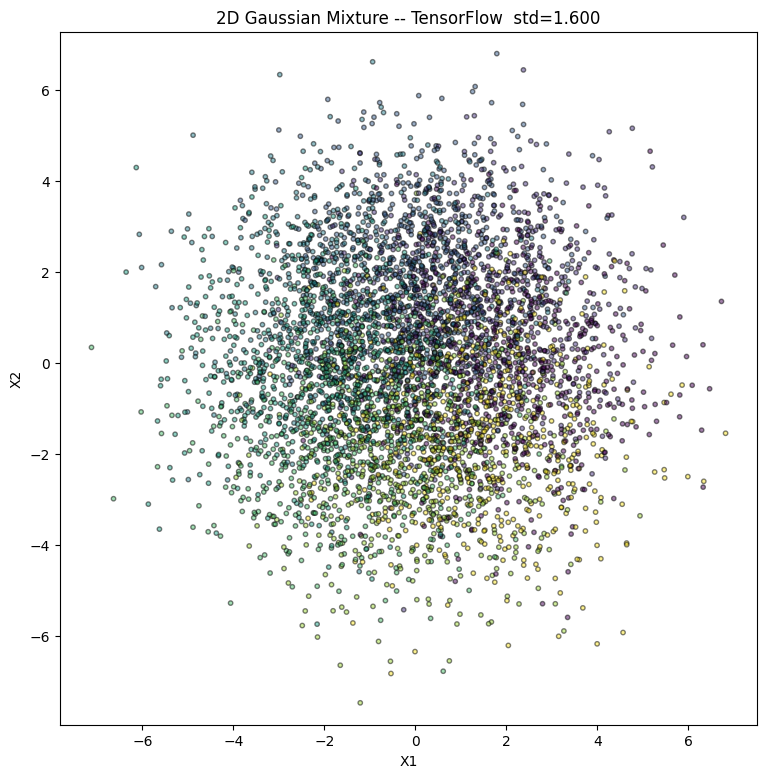


covariance matrix:
[[4.6068215  0.01249994]
 [0.01249994 4.684886  ]]

Empirical mean:
[-0.03723663  0.02574243]

Empirical covariance:
[[4.6068215  0.01249994]
 [0.01249994 4.684886  ]]



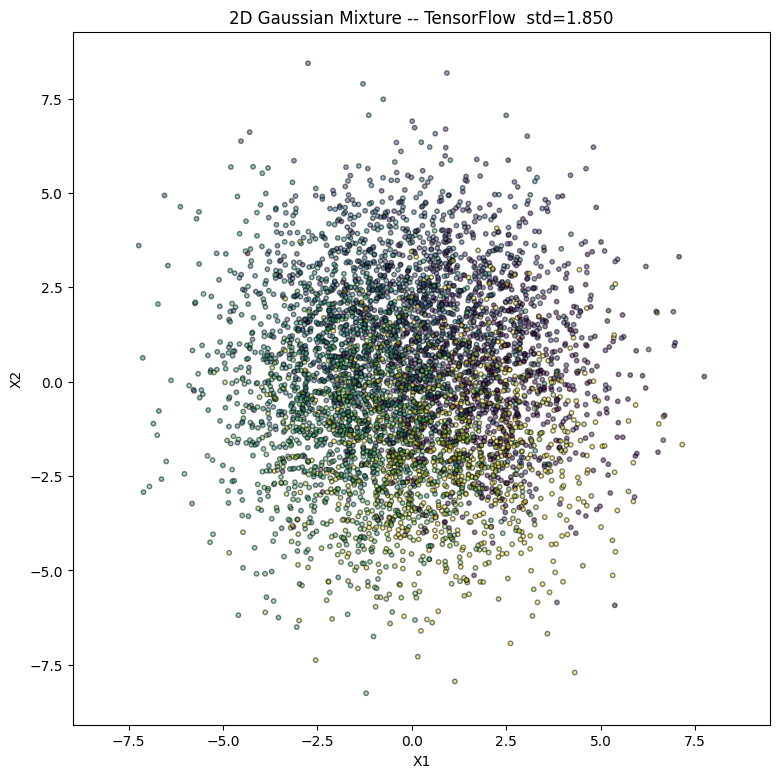


covariance matrix:
[[ 5.189973   -0.12715182]
 [-0.12715182  5.637443  ]]

Empirical mean:
[-0.0609694   0.02385207]

Empirical covariance:
[[ 5.189973   -0.12715182]
 [-0.12715182  5.637443  ]]



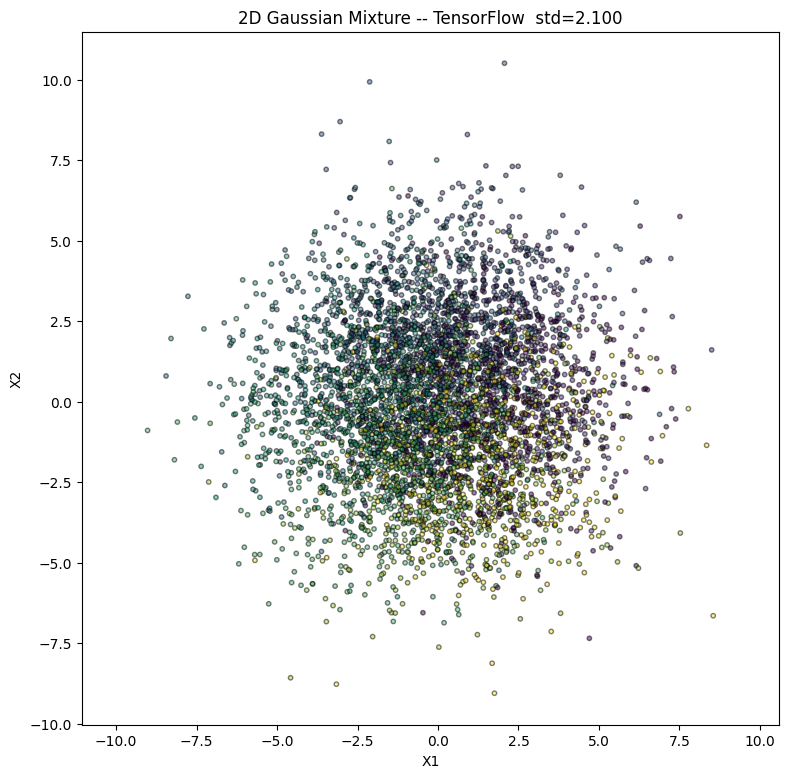


covariance matrix:
[[6.3873916  0.05896284]
 [0.05896284 6.4989657 ]]

Empirical mean:
[ 0.04241487 -0.05660041]

Empirical covariance:
[[6.3873916  0.05896284]
 [0.05896284 6.4989657 ]]



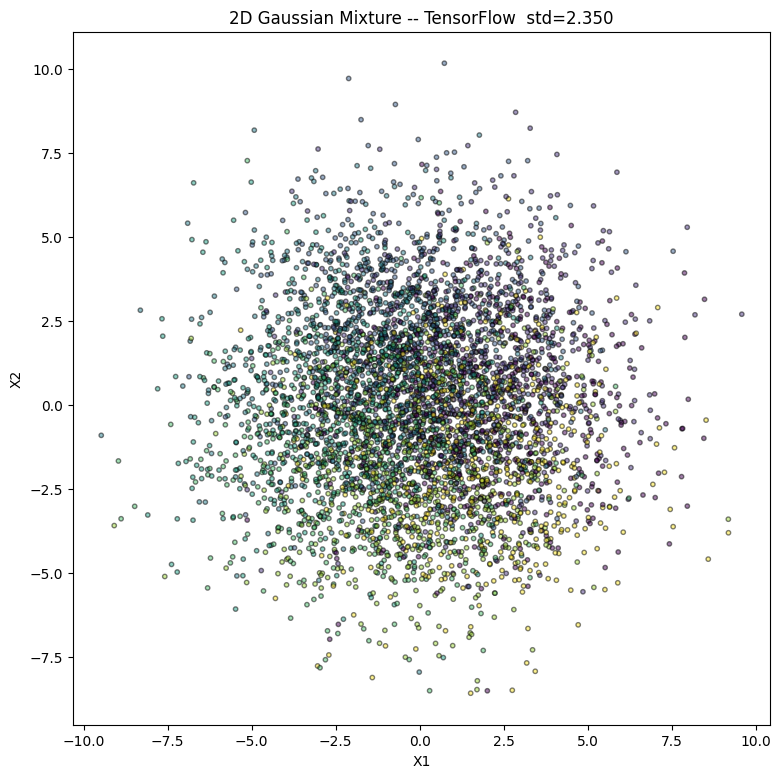


covariance matrix:
[[ 7.5836434  -0.01811415]
 [-0.01811415  7.443219  ]]

Empirical mean:
[-0.0187515   0.00807847]

Empirical covariance:
[[ 7.5836434  -0.01811415]
 [-0.01811415  7.443219  ]]



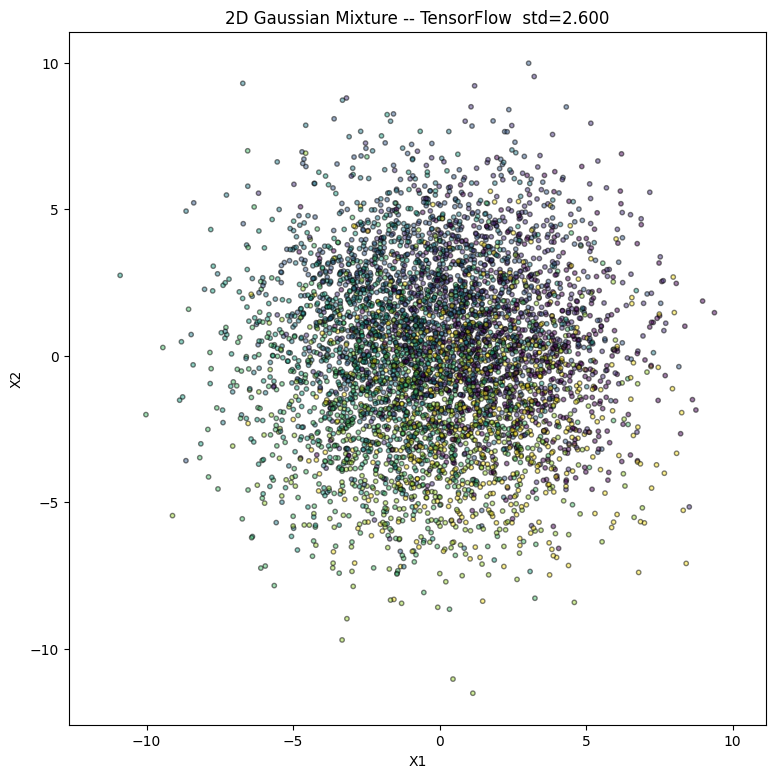


covariance matrix:
[[8.789543   0.02431211]
 [0.02431211 8.724452  ]]

Empirical mean:
[-0.01133148  0.04523826]

Empirical covariance:
[[8.789543   0.02431211]
 [0.02431211 8.724452  ]]



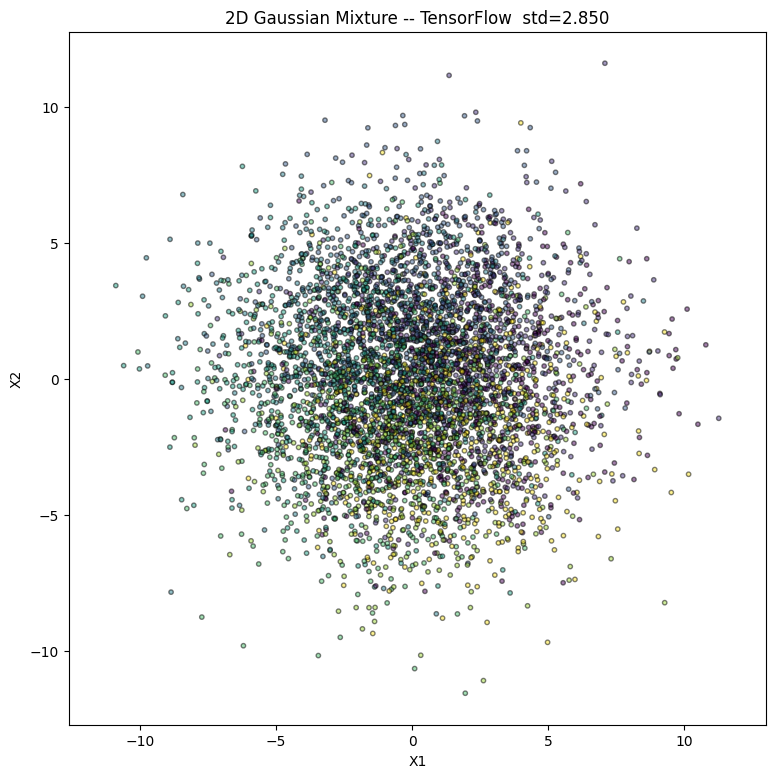


covariance matrix:
[[10.054393   -0.11424843]
 [-0.11424843  9.844491  ]]

Empirical mean:
[ 0.00432104 -0.0007271 ]

Empirical covariance:
[[10.054393   -0.11424843]
 [-0.11424843  9.844491  ]]



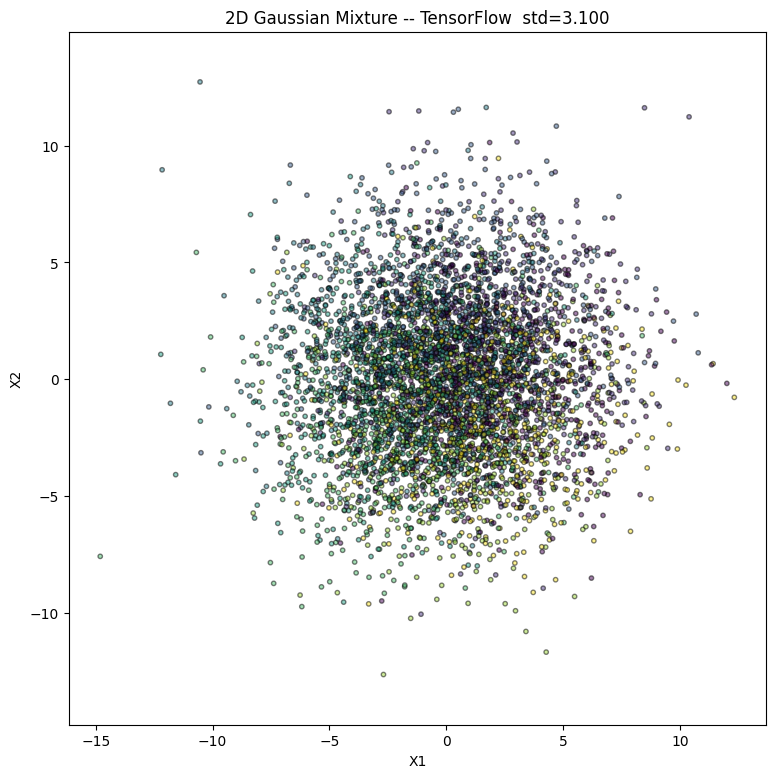


covariance matrix:
[[11.770522   0.3348688]
 [ 0.3348688 11.450556 ]]

Empirical mean:
[-0.04330263 -0.02194258]

Empirical covariance:
[[11.770522   0.3348688]
 [ 0.3348688 11.450556 ]]



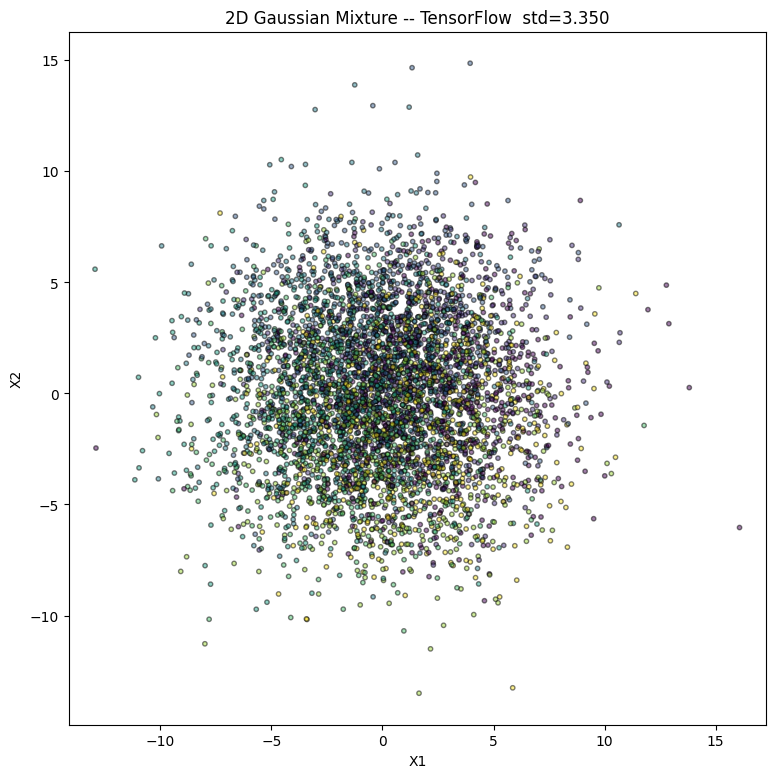


covariance matrix:
[[12.889386    0.10564266]
 [ 0.10564266 12.918712  ]]

Empirical mean:
[-0.14580949 -0.0580187 ]

Empirical covariance:
[[12.889386    0.10564266]
 [ 0.10564266 12.918712  ]]



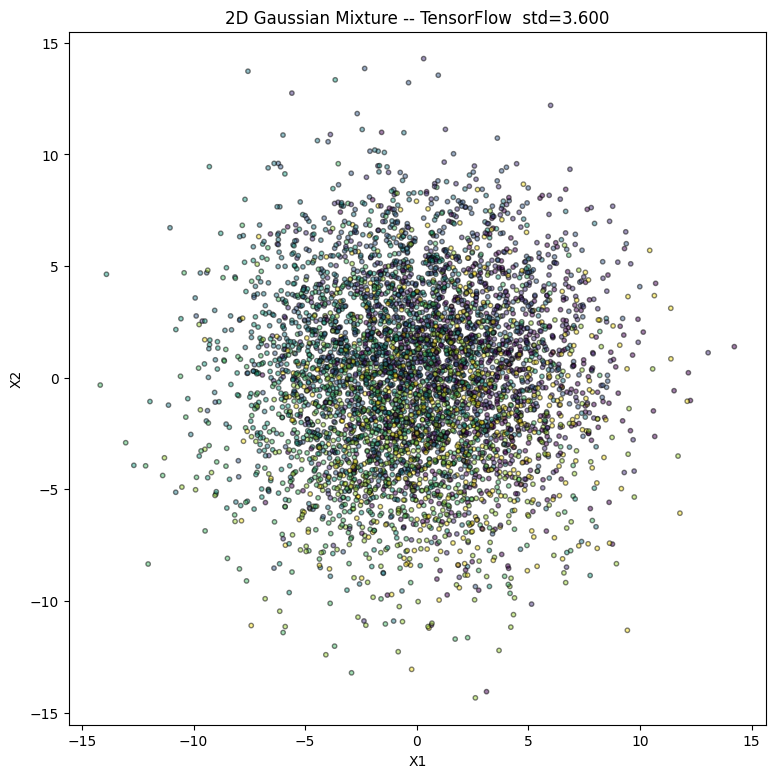


covariance matrix:
[[14.844327    0.20530383]
 [ 0.20530383 15.354273  ]]

Empirical mean:
[-0.04994377  0.09947439]

Empirical covariance:
[[14.844327    0.20530383]
 [ 0.20530383 15.354273  ]]



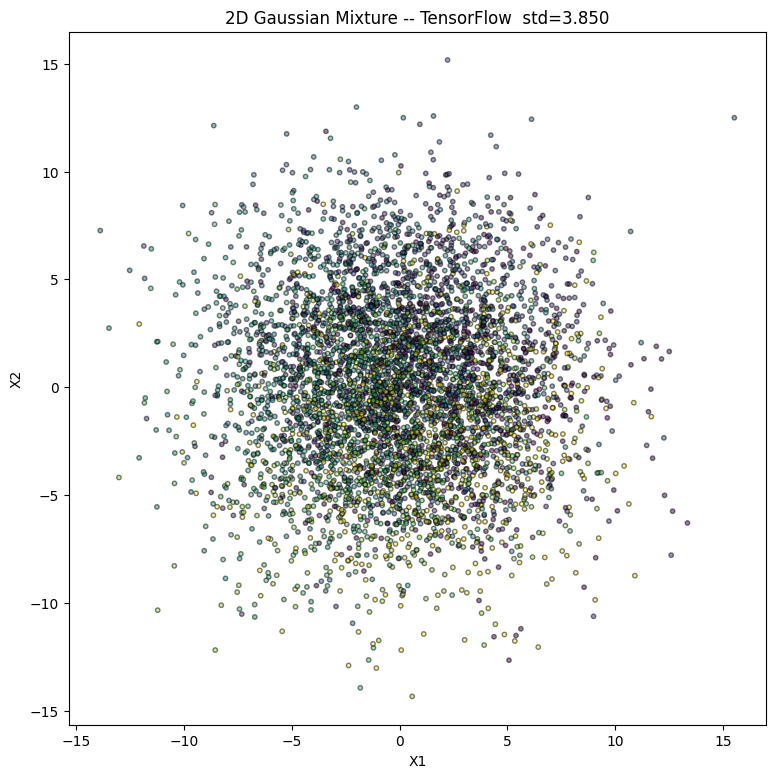


covariance matrix:
[[16.492352   -0.31009716]
 [-0.31009716 17.037907  ]]

Empirical mean:
[ 0.05541211 -0.07571725]

Empirical covariance:
[[16.492352   -0.31009716]
 [-0.31009716 17.037907  ]]



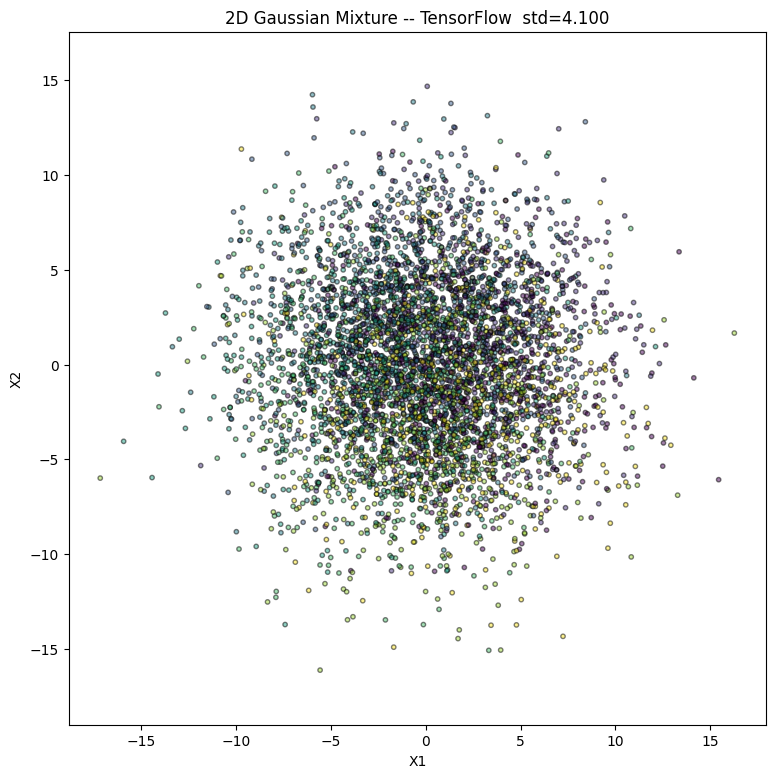


covariance matrix:
[[19.301758   -0.33173046]
 [-0.33173046 19.909063  ]]

Empirical mean:
[0.04582404 0.0286421 ]

Empirical covariance:
[[19.301758   -0.33173046]
 [-0.33173046 19.909063  ]]



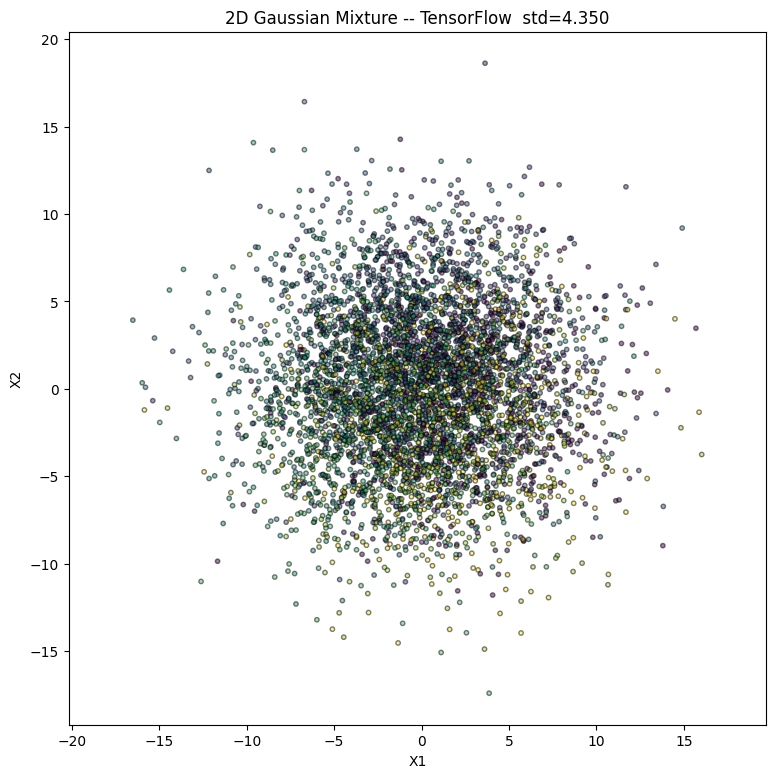


covariance matrix:
[[21.315067   -0.06812046]
 [-0.06812046 20.044743  ]]

Empirical mean:
[ 0.02913655 -0.12047982]

Empirical covariance:
[[21.315067   -0.06812046]
 [-0.06812046 20.044743  ]]



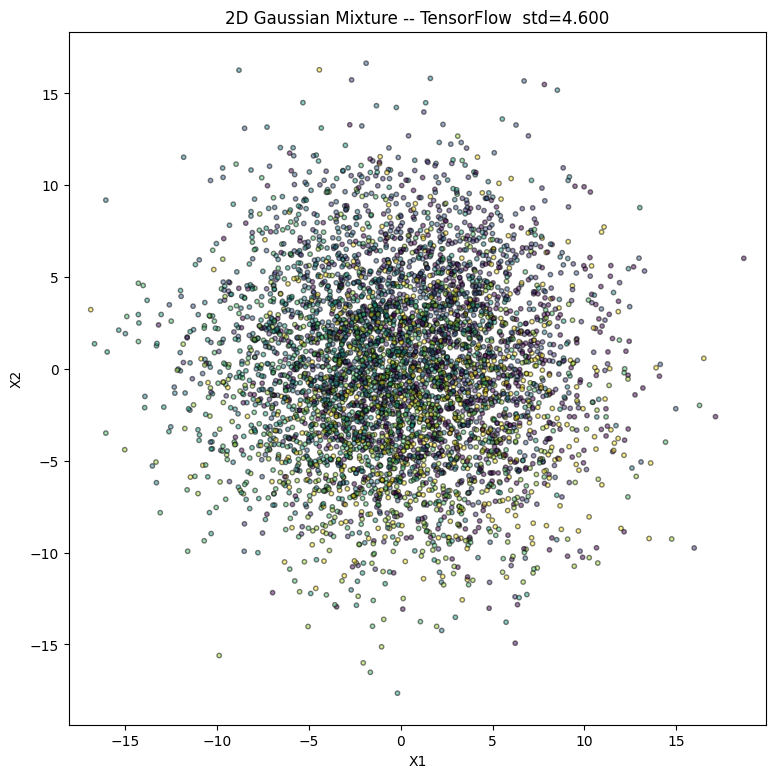


covariance matrix:
[[24.015652  -0.5076193]
 [-0.5076193 23.625057 ]]

Empirical mean:
[ 0.04028547 -0.00635263]

Empirical covariance:
[[24.015652  -0.5076193]
 [-0.5076193 23.625057 ]]



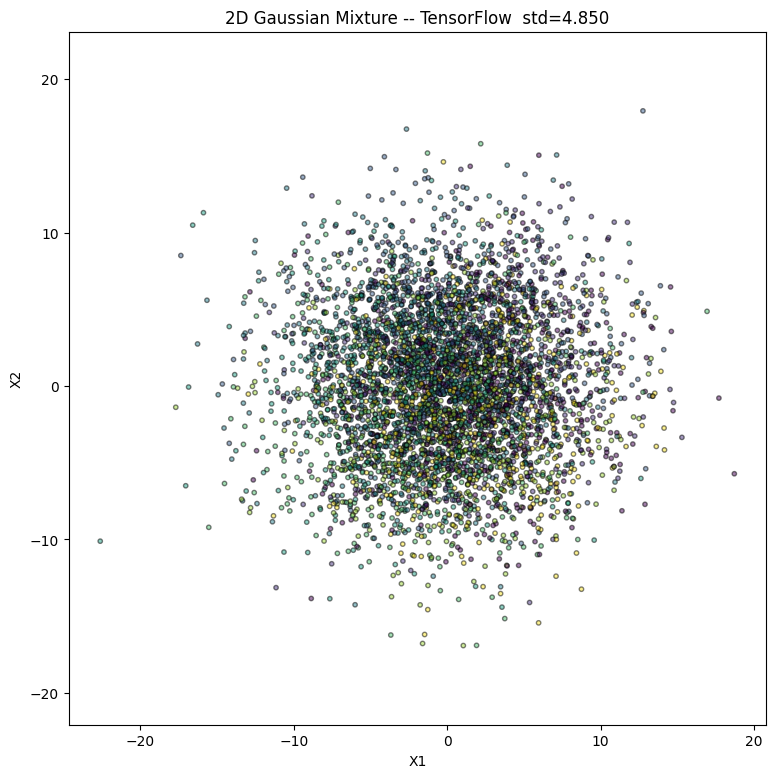


covariance matrix:
[[25.884632    0.53803194]
 [ 0.53803194 24.302988  ]]

Empirical mean:
[-0.07696777 -0.04279466]

Empirical covariance:
[[25.884632    0.53803194]
 [ 0.53803194 24.302988  ]]



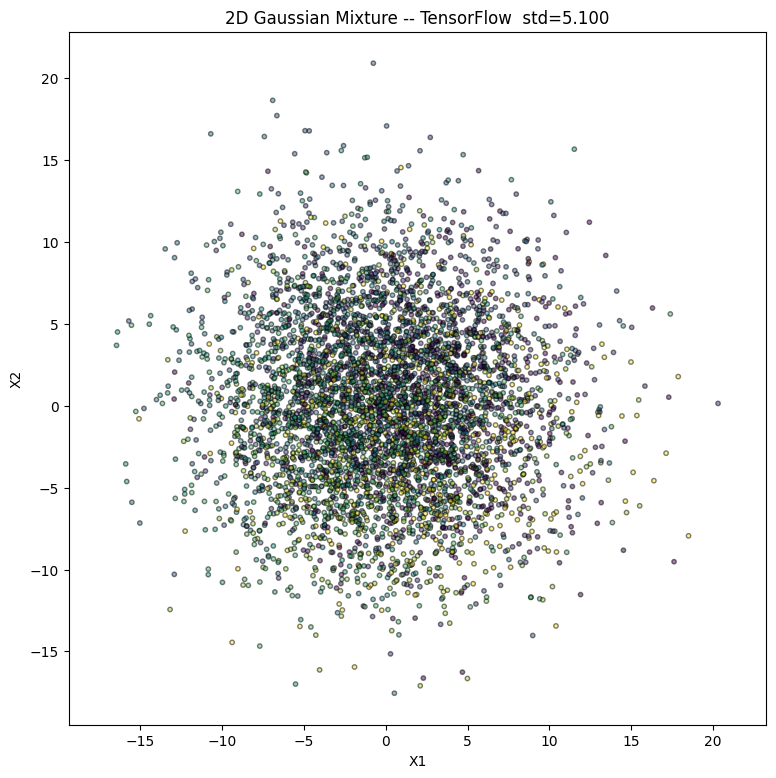


covariance matrix:
[[27.425398  -0.5232778]
 [-0.5232778 27.738466 ]]

Empirical mean:
[-0.0373575  -0.01342724]

Empirical covariance:
[[27.425398  -0.5232778]
 [-0.5232778 27.738466 ]]



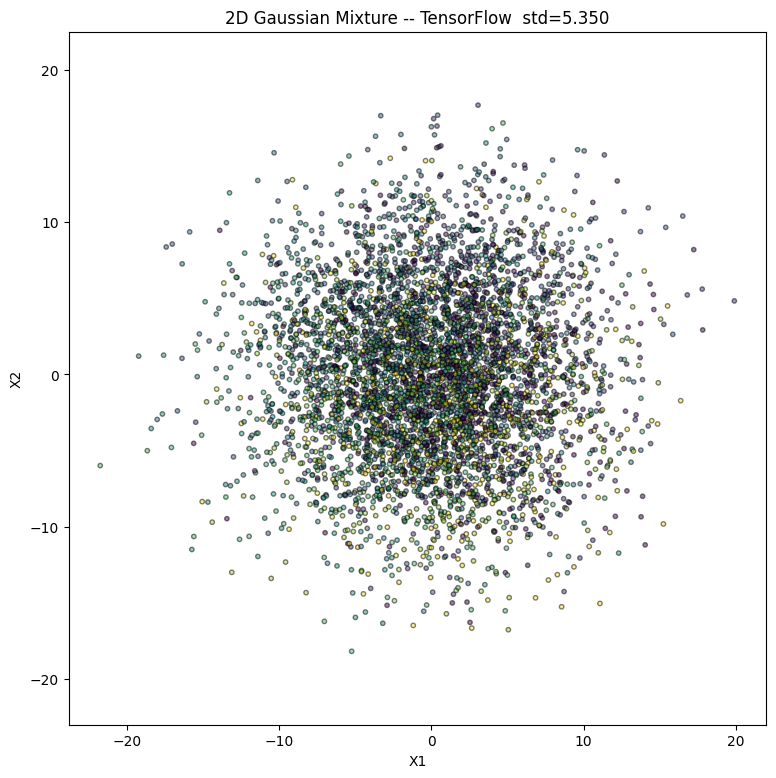


covariance matrix:
[[3.0473238e+01 9.8986309e-03]
 [9.8986309e-03 3.0726496e+01]]

Empirical mean:
[0.0402554  0.05041329]

Empirical covariance:
[[3.0473238e+01 9.8986309e-03]
 [9.8986309e-03 3.0726496e+01]]



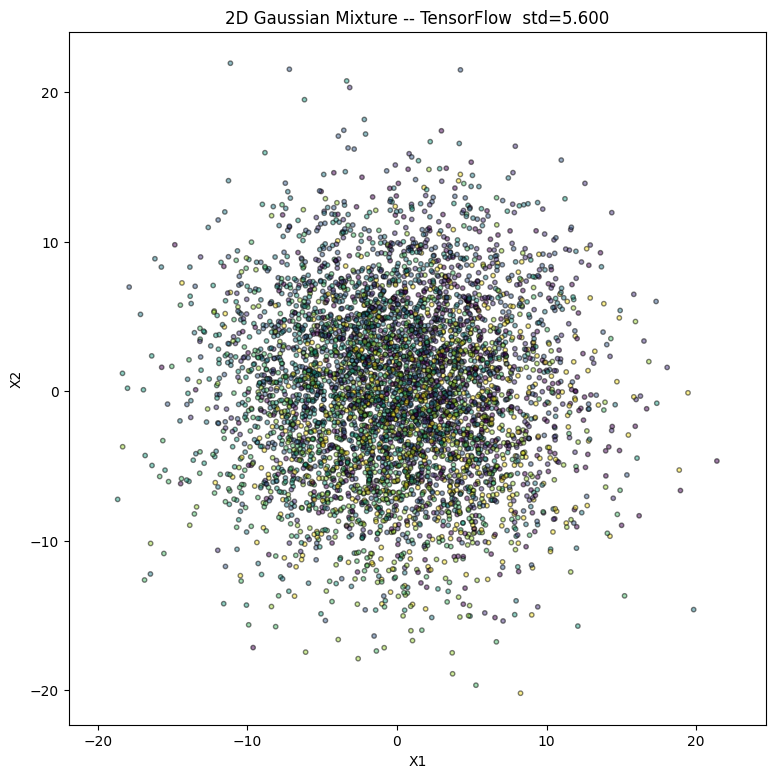


covariance matrix:
[[32.718082   -0.20742947]
 [-0.20742947 34.158833  ]]

Empirical mean:
[-0.12923196 -0.06174545]

Empirical covariance:
[[32.718082   -0.20742947]
 [-0.20742947 34.158833  ]]



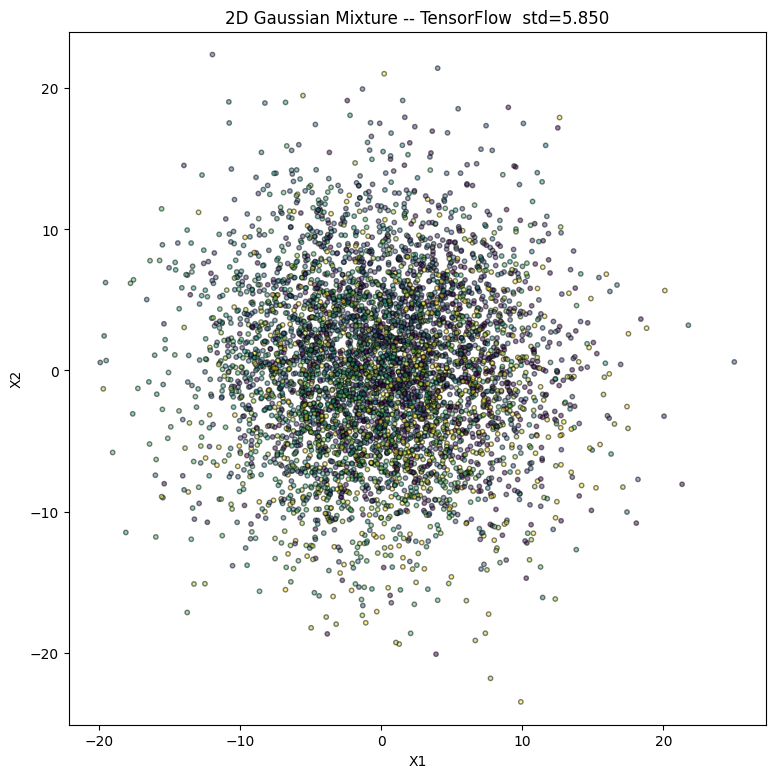


covariance matrix:
[[35.760212   -0.54535973]
 [-0.54535973 36.628418  ]]

Empirical mean:
[-0.00010288  0.02753575]

Empirical covariance:
[[35.760212   -0.54535973]
 [-0.54535973 36.628418  ]]



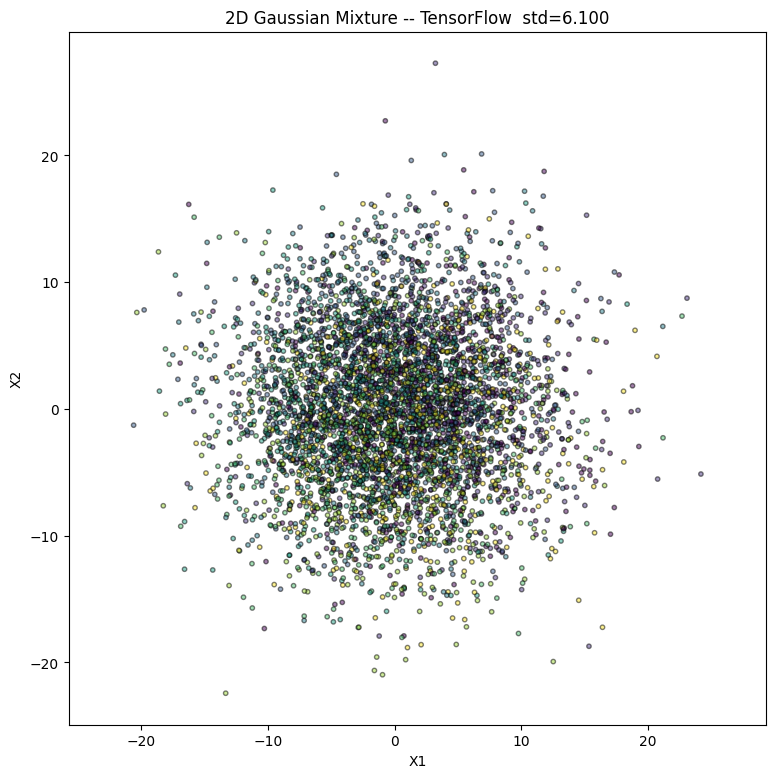


covariance matrix:
[[39.073277   -0.05008649]
 [-0.05008649 39.432606  ]]

Empirical mean:
[0.02817226 0.01862305]

Empirical covariance:
[[39.073277   -0.05008649]
 [-0.05008649 39.432606  ]]



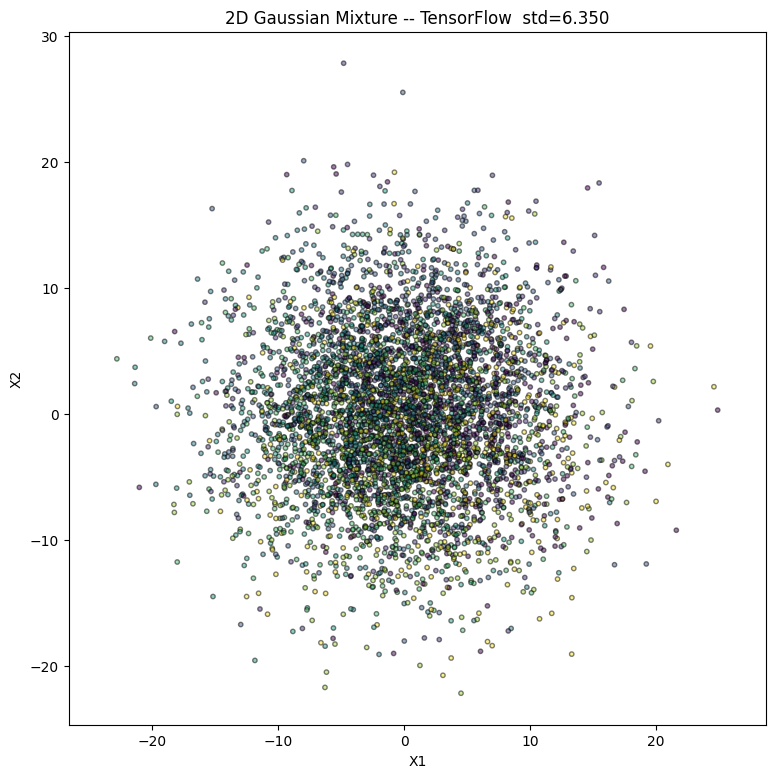


covariance matrix:
[[42.099712   0.2457265]
 [ 0.2457265 40.567566 ]]

Empirical mean:
[0.08116785 0.09362471]

Empirical covariance:
[[42.099712   0.2457265]
 [ 0.2457265 40.567566 ]]



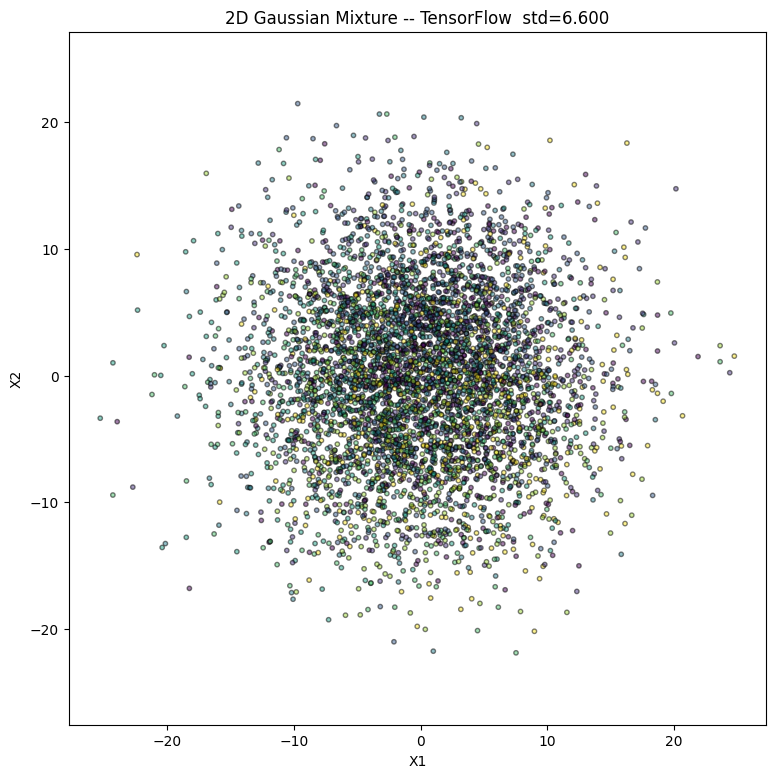


covariance matrix:
[[45.054855    0.06573381]
 [ 0.06573381 46.33174   ]]

Empirical mean:
[0.09648985 0.04214592]

Empirical covariance:
[[45.054855    0.06573381]
 [ 0.06573381 46.33174   ]]



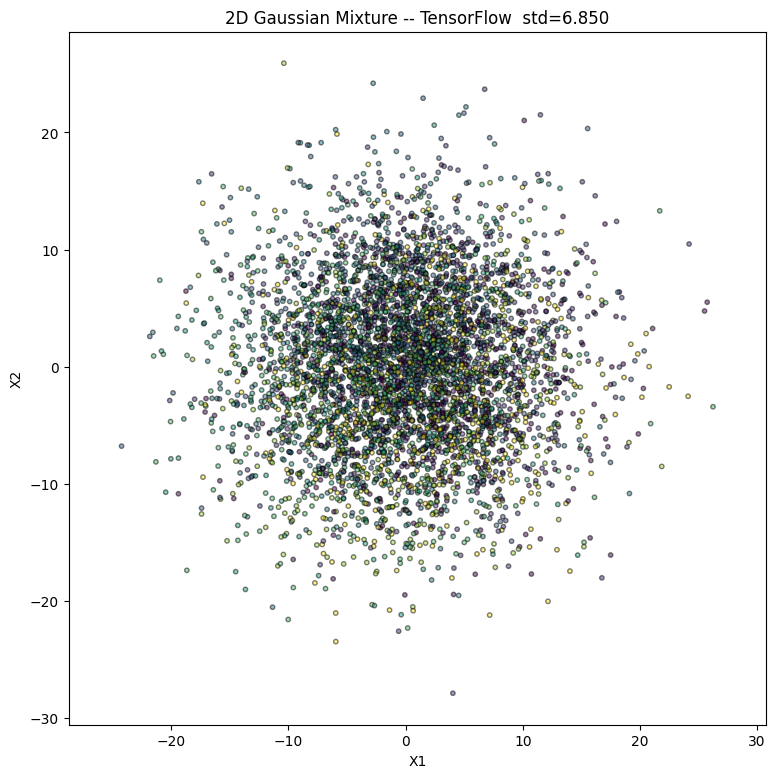


covariance matrix:
[[50.165756   0.6226251]
 [ 0.6226251 49.245335 ]]

Empirical mean:
[0.08735832 0.12497937]

Empirical covariance:
[[50.165756   0.6226251]
 [ 0.6226251 49.245335 ]]



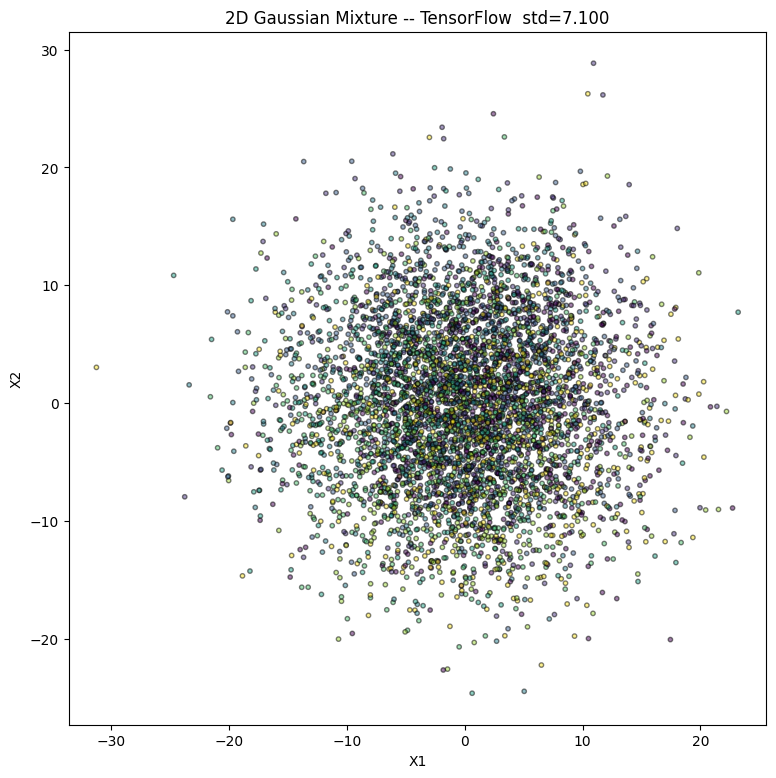


covariance matrix:
[[51.030293    0.07886826]
 [ 0.07886826 53.105434  ]]

Empirical mean:
[ 0.08131453 -0.13814943]

Empirical covariance:
[[51.030293    0.07886826]
 [ 0.07886826 53.105434  ]]



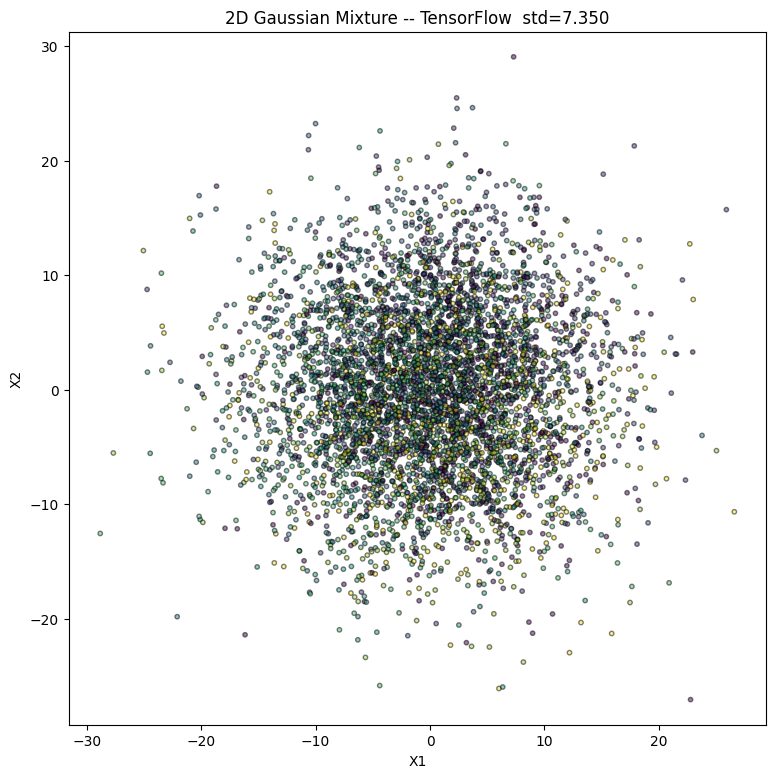


covariance matrix:
[[5.7658619e+01 1.1500728e-02]
 [1.1500728e-02 5.6026112e+01]]

Empirical mean:
[ 0.1446785  -0.02689359]

Empirical covariance:
[[5.7658619e+01 1.1500728e-02]
 [1.1500728e-02 5.6026112e+01]]



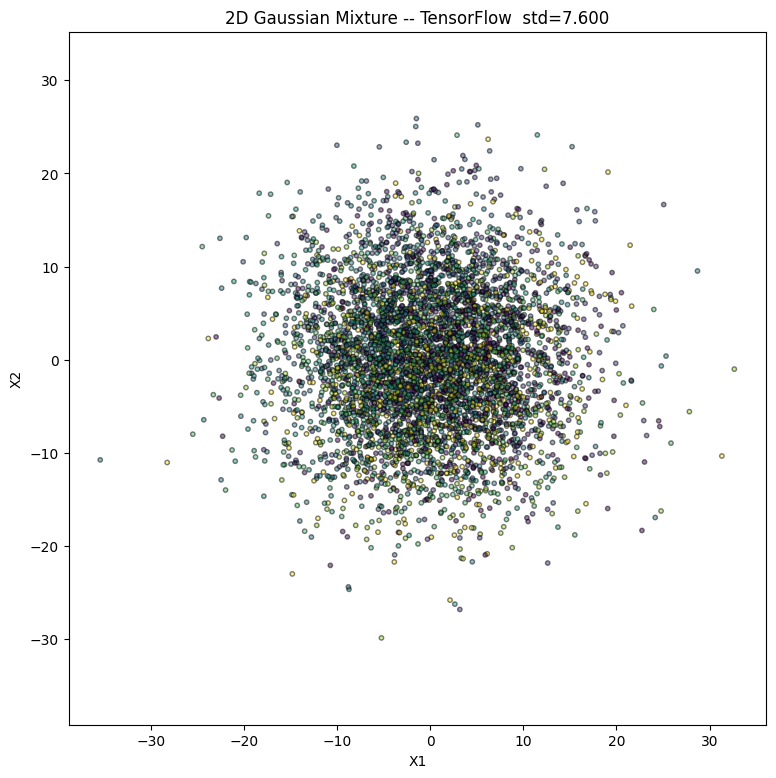


covariance matrix:
[[60.938538   -0.47396934]
 [-0.47396934 58.5708    ]]

Empirical mean:
[0.02380879 0.03245687]

Empirical covariance:
[[60.938538   -0.47396934]
 [-0.47396934 58.5708    ]]



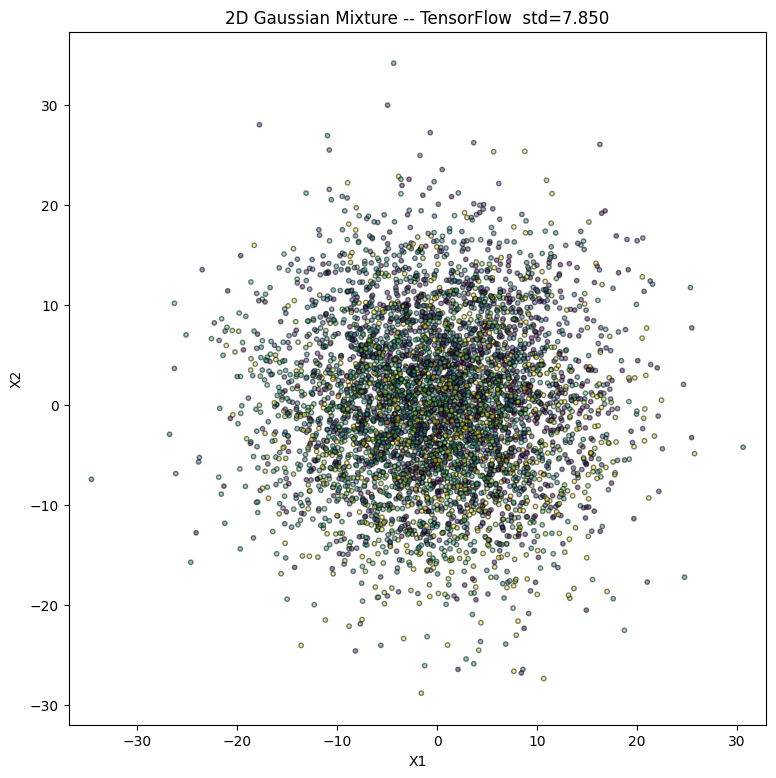


covariance matrix:
[[63.41674    -0.30095923]
 [-0.30095923 65.61672   ]]

Empirical mean:
[ 0.07350204 -0.04354697]

Empirical covariance:
[[63.41674    -0.30095923]
 [-0.30095923 65.61672   ]]



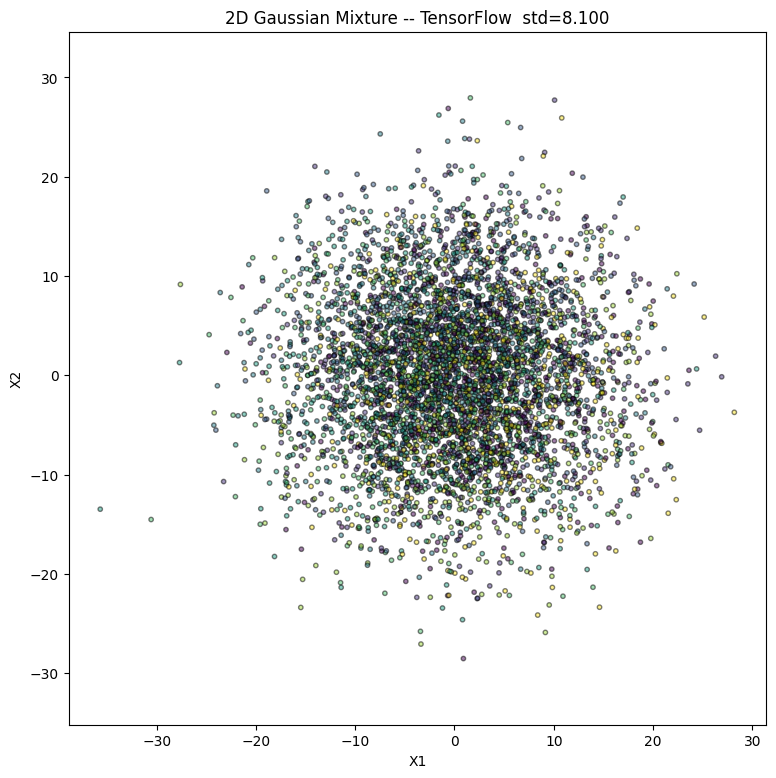


covariance matrix:
[[68.9666    -1.0367544]
 [-1.0367544 66.192535 ]]

Empirical mean:
[0.05663479 0.02187765]

Empirical covariance:
[[68.9666    -1.0367544]
 [-1.0367544 66.192535 ]]



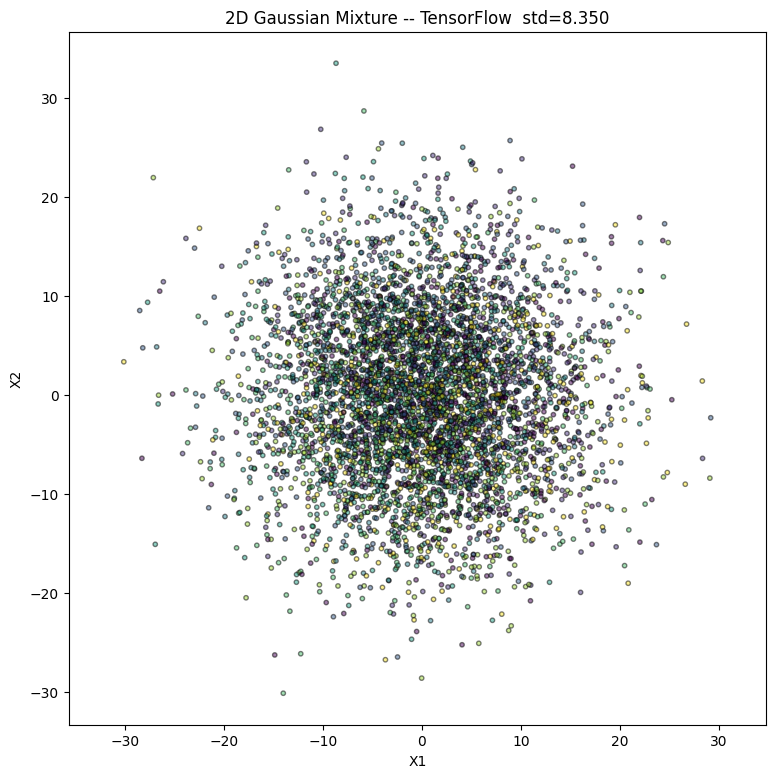


covariance matrix:
[[71.21657   -0.9193675]
 [-0.9193675 71.67294  ]]

Empirical mean:
[ 0.0469379  -0.00802025]

Empirical covariance:
[[71.21657   -0.9193675]
 [-0.9193675 71.67294  ]]



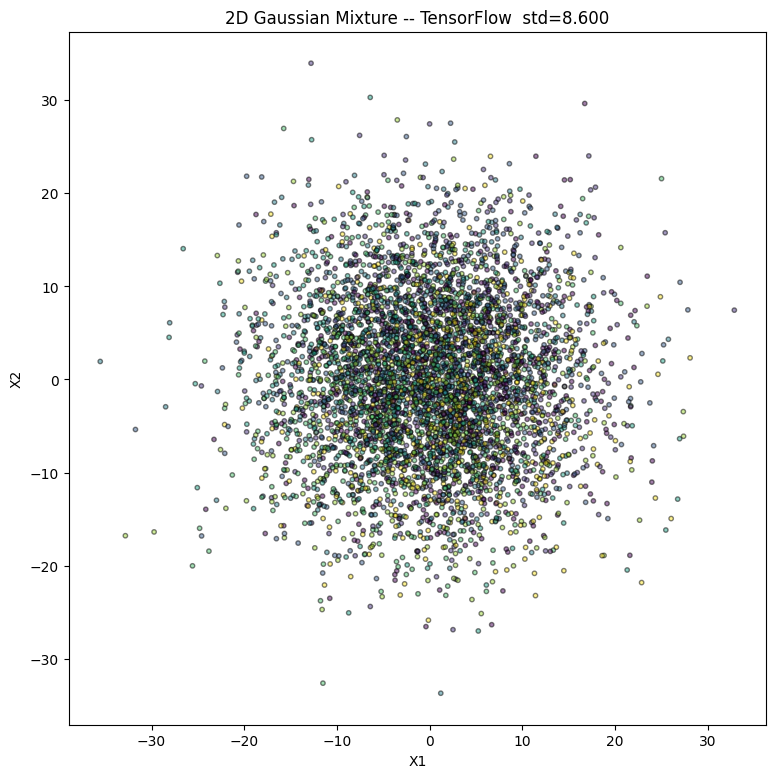


covariance matrix:
[[ 7.5606567e+01 -3.5880394e-02]
 [-3.5880394e-02  7.7272354e+01]]

Empirical mean:
[0.06506662 0.08933046]

Empirical covariance:
[[ 7.5606567e+01 -3.5880394e-02]
 [-3.5880394e-02  7.7272354e+01]]



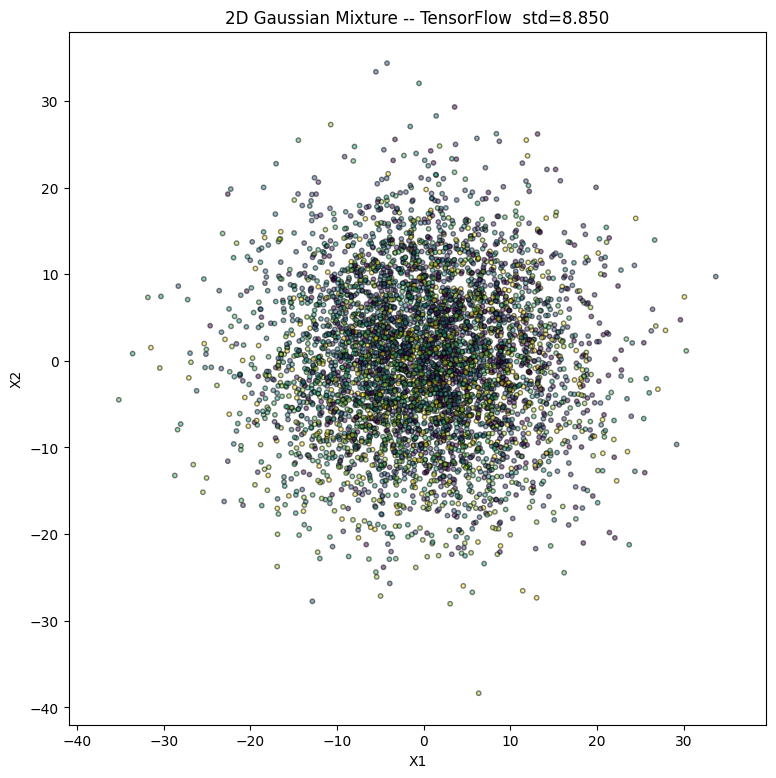


covariance matrix:
[[8.0370636e+01 2.2244269e-02]
 [2.2244269e-02 7.6903908e+01]]

Empirical mean:
[-0.35570717  0.11030405]

Empirical covariance:
[[8.0370636e+01 2.2244269e-02]
 [2.2244269e-02 7.6903908e+01]]



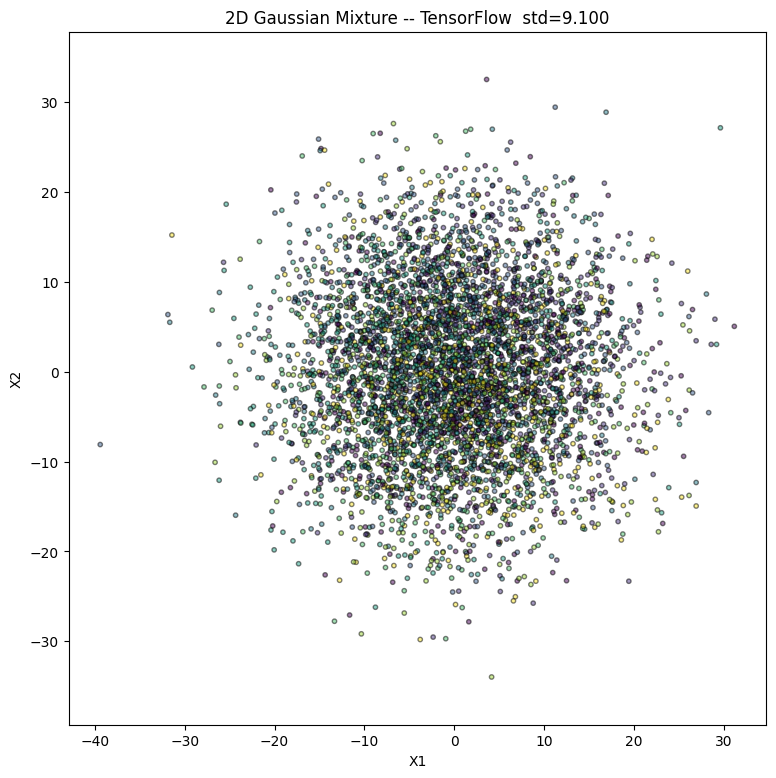


covariance matrix:
[[85.94279     0.20284495]
 [ 0.20284495 86.032585  ]]

Empirical mean:
[ 0.04213857 -0.04052137]

Empirical covariance:
[[85.94279     0.20284495]
 [ 0.20284495 86.032585  ]]



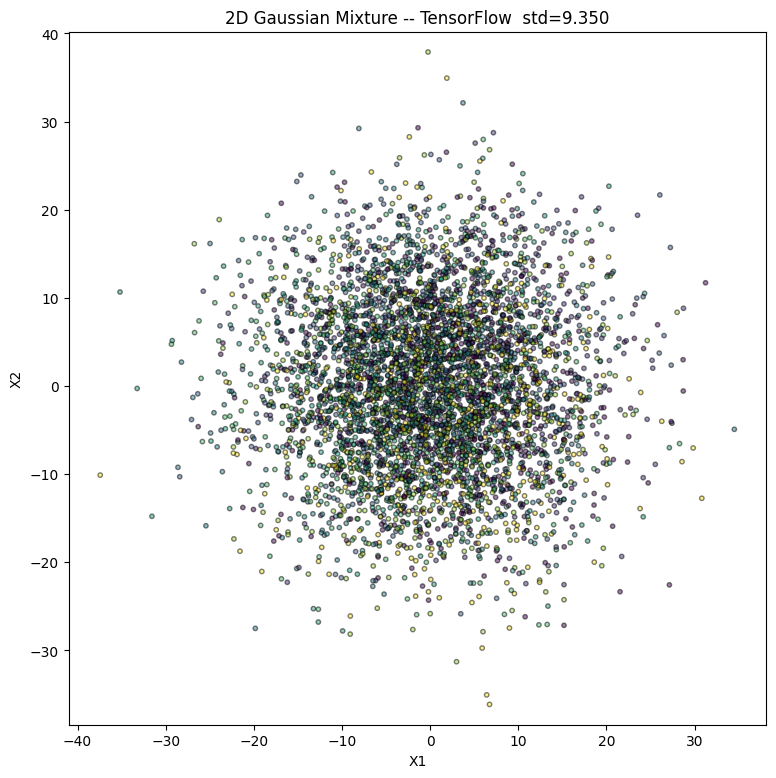


covariance matrix:
[[89.43703   -0.4674981]
 [-0.4674981 91.441605 ]]

Empirical mean:
[ 0.01413004 -0.02954738]

Empirical covariance:
[[89.43703   -0.4674981]
 [-0.4674981 91.441605 ]]



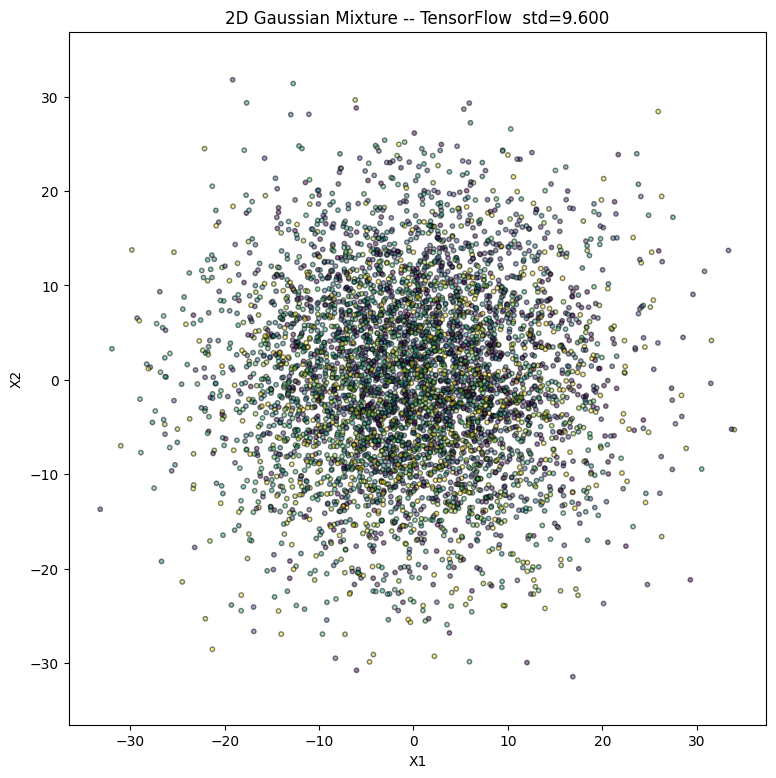


covariance matrix:
[[95.803474   1.2110026]
 [ 1.2110026 93.42214  ]]

Empirical mean:
[ 0.14413367 -0.16463518]

Empirical covariance:
[[95.803474   1.2110026]
 [ 1.2110026 93.42214  ]]



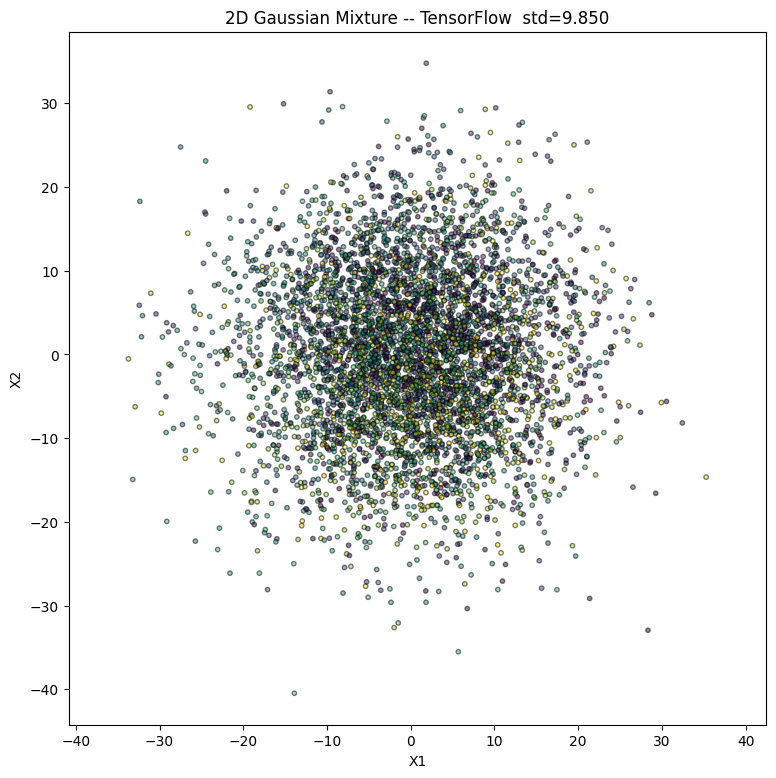


covariance matrix:
[[98.03467     0.42034906]
 [ 0.42034906 98.52284   ]]

Empirical mean:
[0.00447249 0.16675496]

Empirical covariance:
[[98.03467     0.42034906]
 [ 0.42034906 98.52284   ]]



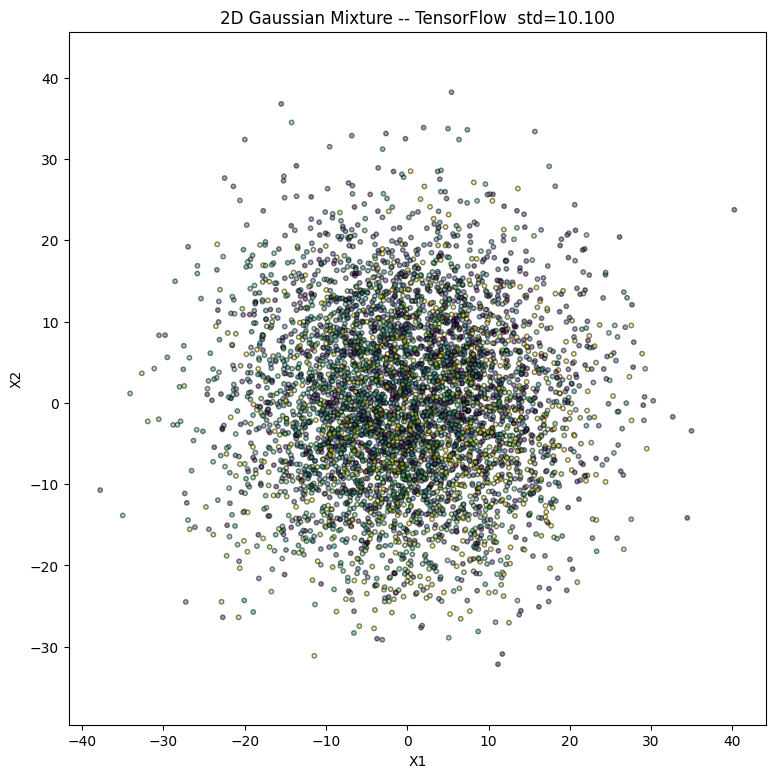


covariance matrix:
[[103.62381    -1.0762647]
 [ -1.0762647 108.31393  ]]

Empirical mean:
[-0.18789987 -0.16529405]

Empirical covariance:
[[103.62381    -1.0762647]
 [ -1.0762647 108.31393  ]]



In [16]:
sigmas = np.arange(.1, 10.25, .25)

for sigma in sigmas:
  X, labels, cov = make_data(n_samples, sigma, centers)

#### Replace four clusters with eight equally spaced centers on a circle of radius 2

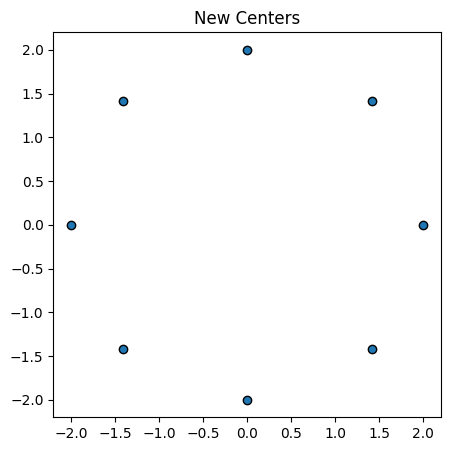

In [17]:
angles = np.arange(0, 360, 360/8) * np.pi/180

centers = tf.constant([
    [2 * np.cos(angles[0]), 2 * np.sin(angles[0])],
    [2 * np.cos(angles[1]), 2 * np.sin(angles[1])],
    [2 * np.cos(angles[2]), 2 * np.sin(angles[2])],
    [2 * np.cos(angles[3]), 2 * np.sin(angles[3])],
    [2 * np.cos(angles[4]), 2 * np.sin(angles[4])],
    [2 * np.cos(angles[5]), 2 * np.sin(angles[5])],
    [2 * np.cos(angles[6]), 2 * np.sin(angles[6])],
    [2 * np.cos(angles[7]), 2 * np.sin(angles[7])],
], dtype=tf.float32)

plt.figure(figsize=(5, 5))
plt.scatter(centers[:, 0], centers[:, 1], ec='k'),
plt.title('New Centers')
plt.show();


covariance matrix:
[[ 2.0395021  -0.01914582]
 [-0.01914582  2.0036297 ]]

Empirical mean:
[0.00903534 0.04845005]

Empirical covariance:
[[ 2.0395021  -0.01914582]
 [-0.01914582  2.0036297 ]]



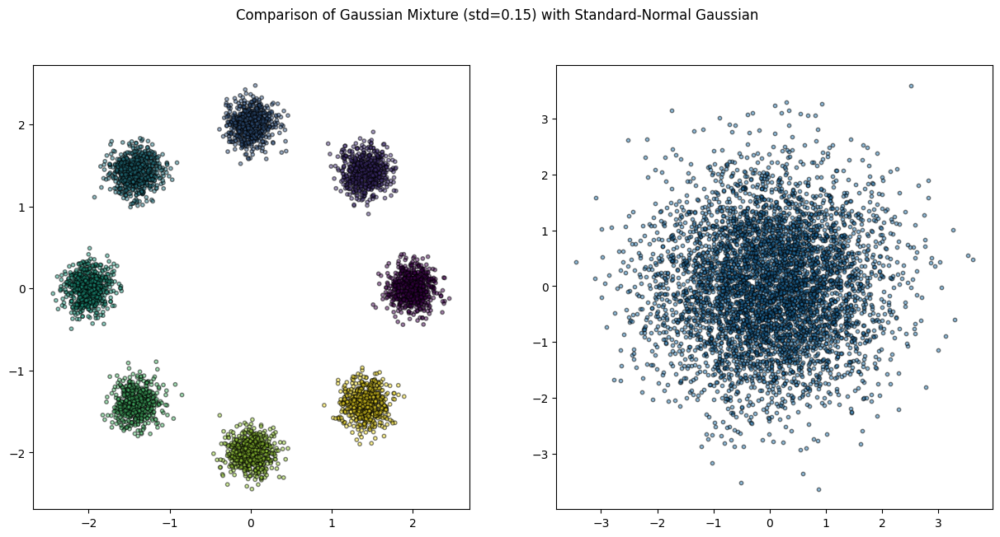


covariance matrix:
[[ 2.0947134  -0.01613105]
 [-0.01613105  2.0777767 ]]

Empirical mean:
[ 0.02677841 -0.00083649]

Empirical covariance:
[[ 2.0947134  -0.01613105]
 [-0.01613105  2.0777767 ]]



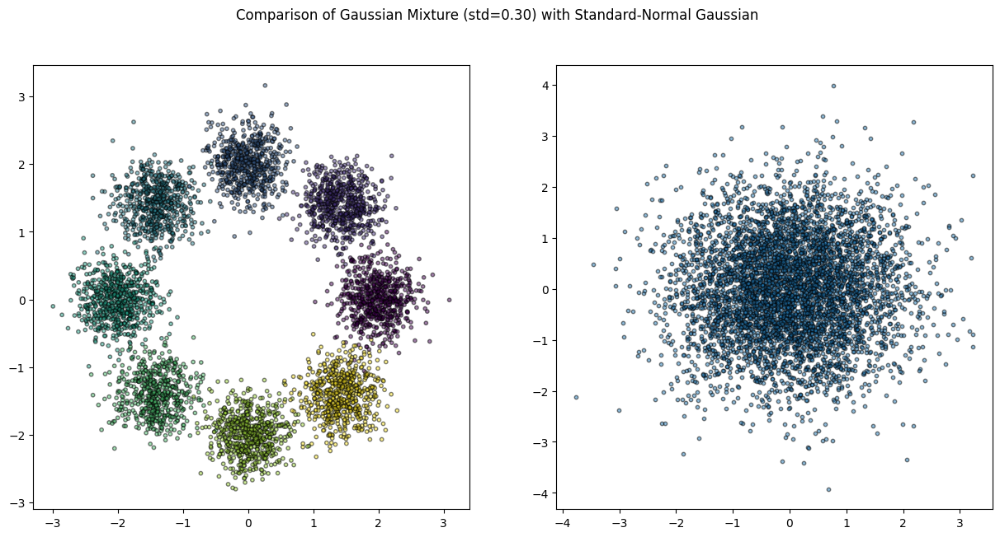


covariance matrix:
[[ 2.2504258  -0.01825983]
 [-0.01825983  2.2601626 ]]

Empirical mean:
[-0.00392602 -0.01167819]

Empirical covariance:
[[ 2.2504258  -0.01825983]
 [-0.01825983  2.2601626 ]]



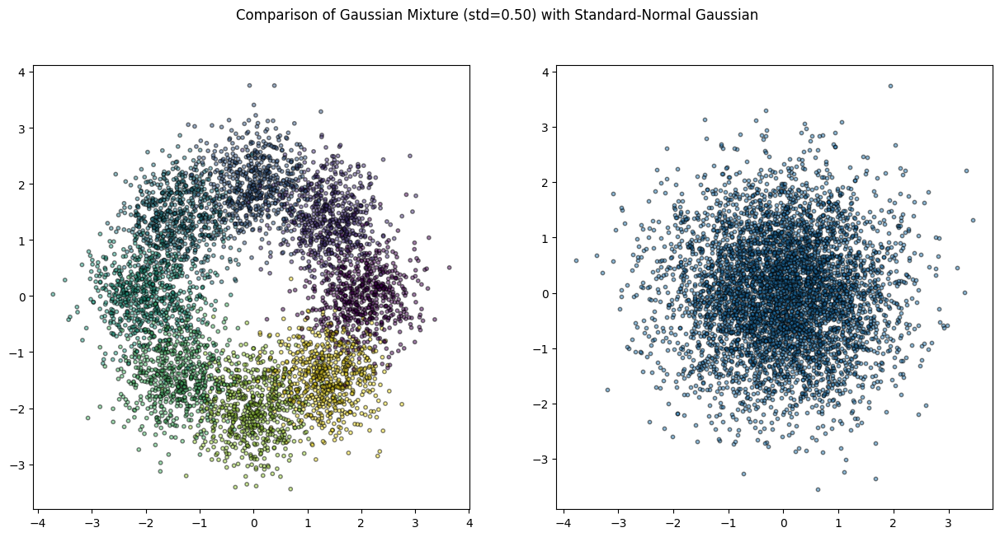


covariance matrix:
[[ 2.4668856  -0.01896406]
 [-0.01896406  2.4774237 ]]

Empirical mean:
[0.0075856  0.03369229]

Empirical covariance:
[[ 2.4668856  -0.01896406]
 [-0.01896406  2.4774237 ]]



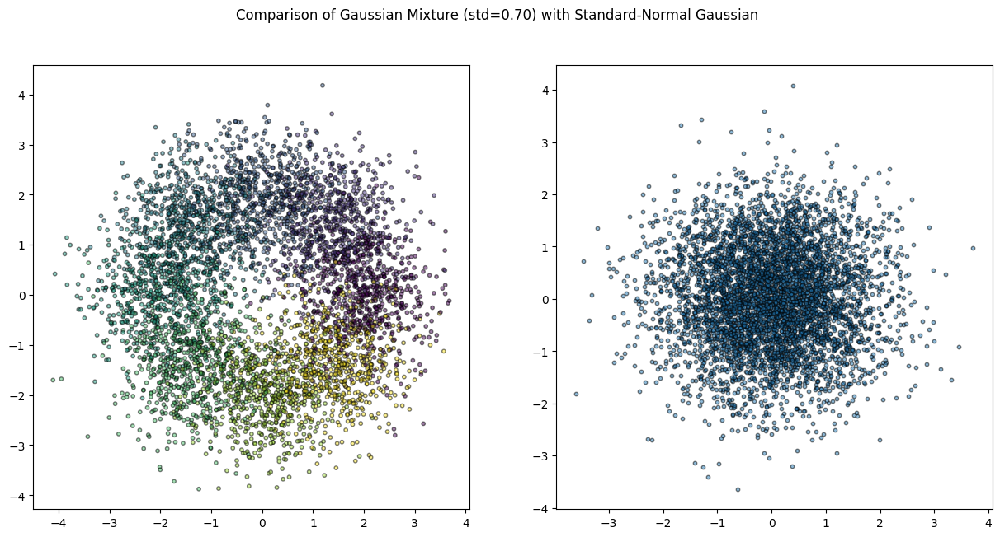


covariance matrix:
[[3.0384219  0.01759909]
 [0.01759909 2.9675808 ]]

Empirical mean:
[0.01876572 0.01774125]

Empirical covariance:
[[3.0384219  0.01759909]
 [0.01759909 2.9675808 ]]



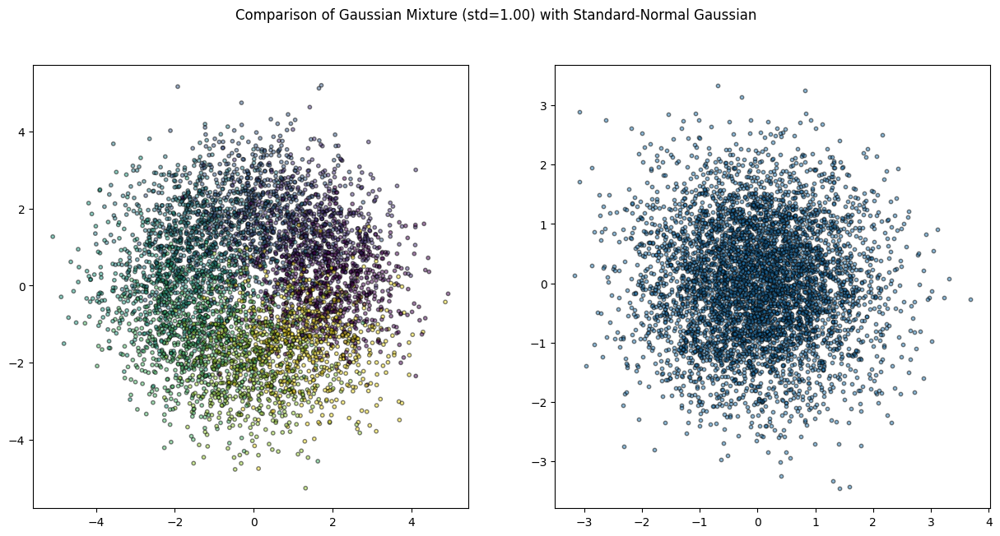

In [18]:
stds = [.15, .3, .5, .7, 1]

for std in stds:
  data = make_data(n_samples, sigma=std, centers=centers, plot=False)
  normal_sample = tf.random.normal((5000,2) )

  fig, ax = plt.subplots(1, 2, figsize=(15, 7))
  ax[0].scatter(data[0][:, 0], data[0][:,1], ec='k', alpha=.5, s=10,
                c=data[1])
  ax[1].scatter(normal_sample[:, 0], normal_sample[:, 1], ec='k', s=10,
                alpha=.5)
  plt.suptitle(f'Comparison of Gaussian Mixture (std={std:.2f}) with Standard-Normal Gaussian')
  plt.show();

For the eight equally spaced centers on the circle of radius $2$:
<center>$\Large \Sigma = \left(  2 + \sigma^2 \right)I$</center>

## 6. References
Understanding Deep Learning — Simon Prince — Probability, neural networks, generative modeling.
https://udlbook.github.io/udlbook/

Probabilistic Machine Learning — Kevin Murphy — Gaussians, mixtures, KL divergence, probabilistic models.
https://probml.github.io/pml-book/

Mathematics for Machine Learning — Probability, matrix calculus, optimization.
https://mml-book.github.io/

Deep Learning — Goodfellow, Bengio, Courville — Probability and generative model background.
https://www.deeplearningbook.org/

Dive into Deep Learning — Neural-network foundations; adapt examples to TensorFlow.
https://d2l.ai/

Neural Ordinary Differential Equations — Introduction and ODE formulation.
https://arxiv.org/abs/1806.07366

Denoising Diffusion Probabilistic Models — Preview the abstract and introduction.
https://arxiv.org/abs/2006.11239

Flow Matching for Generative Modeling — Preview the abstract and introduction.
https://arxiv.org/abs/2210.02747

# 7. Knowledge Check
1. What is the primary objective of a generative model?
   * Answer: Represent or sample from the data distribution.

2. What does a Gaussian covariance matrix describe?
    * Answer: Variances and relationships between dimensions.

3. Is KL divergence symmetric?
    * Answer: No. $D_{KL}(p||q)$ generally differs from $D_{KL}(q||p)$.

4. How does an SDE differ from an ODE?
    * Answer: An SDE includes a stochastic driving term.

5. What does a flow-matching neural network predict?
    * Answer: A time-dependent velocity vector.

# 8. Completion Criteria

Gaussian noise is a natural starting point because, as seen in the progression of plots above, when the standard deviation is large enough even separate classes begin to overlap one another; they mix together on the plot and lose their individual cluster integrity. This leads to a plot of separate classes all blurred together in a blob, as though it were created from a simple normal distirubtion.

It is also easy to sample, mathematically well-behaved, and serves as a reference distribution from which a learned transformation can generate complex samples. In diffusion models specifically, the forward process is designed to approach a tractable Gaussian reference distribution as the original signal is progressively attenuated.

